# Thực nghiệm Chuyên sâu & Mở rộng (Mục 1.1.3 & 1.2.4): Phân tích Ablation $(r, N)$, Hiện tượng Phân mảnh khi $r = 0$, và Hạn chế của Khoảng cách Euclidean trước Dữ liệu Hỗn hợp (Nominal / Binary)

Notebook này mở rộng thực nghiệm từ bài báo **"KNN Model-Based Approach in Classification" (Guo et al., 2003)** nhằm kiểm chứng thực nghiệm hai hạn chế kỹ thuật cốt lõi và đề xuất hướng cải tiến cụ thể (phục vụ Mục 1.1.3 và Điểm thưởng Mục 1.2.4 của đồ án CSC14005):

1. **Phân tích Ablation giữa $r$ (Pruning 2) và $N$ (Pruning 1) — Kiểm chứng hiện tượng Phân mảnh cấu trúc / Overfitting tại $r = 0$**:
   - Khi $r = 0$ và không hậu cắt tỉa ($N = 0$), quá trình mở rộng hình cầu từ mỗi tâm $d_i$ dừng ngay lập tức khi chạm điểm khác nhãn đầu tiên. Điều này ép `KNNModel` đạt **Train Accuracy $\approx 100\%$**, nhưng sinh ra **rất nhiều hình cầu nhỏ và đại diện đơn điểm ($\text{Num} = 1, \text{Sim} = 0$)**, làm **Generalization Gap lớn** và **phá vỡ khả năng nén dữ liệu (RR% tụt mạnh)**.
   - Khác với cách so sánh gộp dễ gây nhiễu biến (*confounding*), ta thực hiện **Ablation tách bạch**: cố định $N = 0$ khi tăng $r \in \{0, 1, 2, 3, 4\}$ (cô lập tác động thuần của $r$) và so sánh song song với $N = 1$ (tác động kết hợp của Pruning 1 và Pruning 2), cùng bài kiểm tra **Tiêm nhiễu nhãn (Label Noise Stress Test)** trên cả 6 bộ dữ liệu (trung bình nhiều seed ngẫu nhiên).

2. **Hạn chế của `KNNModel` dùng khoảng cách Euclidean trước dữ liệu Hỗn hợp (Nominal & Binary) & Đề xuất Cải tiến bằng Gower Distance / HEOM**:
   - Theo **Table 1**, 4 tập (`glass`, `iris`, `wine`, `diabetes`) thuần thuộc tính số, trong khi **`heart`** (3 Nominal, 3 Binary, 7 Numeric) và **`aust`** (4 Nominal, 4 Binary, 6 Numeric) là dữ liệu hỗn hợp.
   - Khi áp dụng Euclidean ($L_2$) lên không gian hỗn hợp, bình phương bước nhảy rời rạc của biến Binary ($1^2 = 1$) và biến Nominal mã hóa One-Hot ($1^2 + 1^2 = 2$) **lấn át hoàn toàn** chênh lệch nhỏ của biến Numeric ($\Delta^2 \approx 0.02$). Đồng thời, trên không gian rời rạc sinh ra tỷ lệ **đồng khoảng cách (Distance Ties)** và **trùng tọa độ ($d = 0$)** cực cao, làm suy yếu cơ chế sắp xếp `np.argsort` và bán kính biên $\text{Sim}(d_i)$ của `KNNModel`.
   - Ta chứng minh tính tương đương đơn điệu giữa $L_1, L_2$, Hamming trên không gian thuần nhị phân OHE, chỉ rõ vì sao không dùng Hamming trên biến liên tục, và **cài đặt thử nghiệm hai độ đo hỗn hợp chuẩn mực là Gower Distance và HEOM** (Wilson & Martinez, 1997 — Tài liệu tham khảo [9] của chính bài báo!) để khắc phục hạn chế đã chỉ ra.

In [1]:
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import numpy as np
import pandas as pd
import scipy
from scipy.spatial.distance import cdist, pdist
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.utils.validation import check_is_fitted

# Tự động định vị thư mục Source để import chung pipeline và model
source_path = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_loader.py").exists()),
    Path.cwd().parent.parent,
)
if str(source_path) not in sys.path:
    sys.path.append(str(source_path))

from data_loader import (
    DATASETS,
    _CATEGORICAL,
    _SHAPES,
    _information_gain,
    load_dataset,
    make_preprocessor,
)
from knn_model import KNNModel, Representative
from baseline.standard_knn import StandardKNN, get_standard_knn

SEED = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
plt.rcParams["figure.dpi"] = 110

print("=== THÔNG TIN MÔI TRƯỜNG THỰC NGHIỆM ===")
print(f"Source path  : {source_path}")
print(f"OS           : {platform.platform()}")
print(f"Python/Libs  : Python {sys.version.split()[0]} | numpy {np.__version__} | scipy {scipy.__version__} | sklearn {sklearn.__version__} | pandas {pd.__version__}")
print(f"Datasets     : {DATASETS}")

=== THÔNG TIN MÔI TRƯỜNG THỰC NGHIỆM ===
Source path  : d:\US\ML-Project\Source
OS           : Windows-10-10.0.19045-SP0
Python/Libs  : Python 3.14.5 | numpy 2.5.5 | scipy 1.18.1 | sklearn 1.9.1 | pandas 3.1.1
Datasets     : ('glass', 'iris', 'heart', 'wine', 'diabetes', 'aust')


In [2]:
# Định nghĩa cấu trúc kiểu dữ liệu của 6 bộ dữ liệu theo Table 1 (Guo et al., 2003)
DATASET_SCHEMA = {
    "glass": {"nominal": (), "binary": (), "numeric": tuple(range(9))},
    "iris": {"nominal": (), "binary": (), "numeric": tuple(range(4))},
    "heart": {
        "nominal": (2, 6, 12),          # chest-pain, electrocardiographic, thal (NN=3)
        "binary": (1, 5, 8),            # sex, fasting-blood-sugar, angina (NB=3)
        "numeric": (0, 3, 4, 7, 9, 10, 11),  # NO=7
    },
    "wine": {"nominal": (), "binary": (), "numeric": tuple(range(13))},
    "diabetes": {"nominal": (), "binary": (), "numeric": tuple(range(8))},
    "aust": {
        "nominal": (3, 4, 5, 11),       # A4, A5, A6, A12 (NN=4)
        "binary": (0, 7, 8, 10),        # A1, A8, A9, A11 (NB=4)
        "numeric": (1, 2, 6, 9, 12, 13),  # A2, A3, A7, A10, A13, A14 (NO=6)
    },
}


def build_preprocessor(
    k: int | str = "all",
    use_ohe: bool = False,
    dataset_name: str | None = None,
) -> Pipeline:
    """Pipeline tiền xử lý cục bộ theo từng fold (đồng bộ với exp.ipynb và data_loader.py)."""
    if use_ohe:
        if dataset_name is None:
            raise ValueError("Cần truyền dataset_name khi use_ohe=True.")
        return make_preprocessor(dataset_name, k=k)

    steps = [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", MinMaxScaler()),
    ]
    if k != "all":
        steps.append(("select", SelectKBest(score_func=_information_gain, k=k)))
    return Pipeline(steps)


def evaluate_model_detailed(
    dataset_name: str,
    clf,
    k: int | str = "all",
    use_ohe: bool = False,
    cv=CV,
    X_override: np.ndarray | None = None,
    y_override: np.ndarray | None = None,
    custom_preprocessor: Pipeline | None = None,
) -> dict:
    """Đánh giá mô hình qua 5-fold CV, thu thập Train/Test Accuracy, Gap và cấu trúc Representative."""
    if X_override is not None and y_override is not None:
        X, y = X_override, y_override
    else:
        X, y = load_dataset(dataset_name)

    prep = (
        custom_preprocessor
        if custom_preprocessor is not None
        else build_preprocessor(k=k, use_ohe=use_ohe, dataset_name=dataset_name)
    )
    pipe = Pipeline([("prep", prep), ("clf", clf)])

    is_knn_model = isinstance(clf, KNNModel)
    res = cross_validate(
        pipe,
        X,
        y,
        cv=cv,
        scoring="accuracy",
        return_train_score=True,
        return_estimator=is_knn_model,
    )

    train_acc = float(res["train_score"].mean() * 100)
    test_acc = float(res["test_score"].mean() * 100)
    out = {
        "train_acc": train_acc,
        "test_acc": test_acc,
        "test_std": float(res["test_score"].std() * 100),
        "gap": train_acc - test_acc,
        "avg_reps": np.nan,
        "rr_mean": 0.0,
        "singleton_pct": np.nan,
        "small_rep_pct": np.nan,
        "avg_sim": np.nan,
        "avg_num": np.nan,
    }

    if is_knn_model:
        estimators = [est.named_steps["clf"] for est in res["estimator"]]
        out["avg_reps"] = float(np.mean([e.n_representatives_ for e in estimators]))
        out["rr_mean"] = float(np.mean([e.reduction_rate_ for e in estimators]))

        singleton_rates, small_rates, mean_sims, mean_nums = [], [], [], []
        for e in estimators:
            nums = np.array([rep.num for rep in e.representatives_], dtype=float)
            sims = np.array([rep.sim for rep in e.representatives_], dtype=float)
            singleton_rates.append(np.mean(nums == 1) * 100)
            small_rates.append(np.mean(nums <= 2) * 100)
            mean_sims.append(np.mean(sims))
            mean_nums.append(np.mean(nums))

        out["singleton_pct"] = float(np.mean(singleton_rates))
        out["small_rep_pct"] = float(np.mean(small_rates))
        out["avg_sim"] = float(np.mean(mean_sims))
        out["avg_num"] = float(np.mean(mean_nums))

    return out

---
## Phần 1: Phân tích Ablation $(r, N)$ & Kiểm chứng Hiện tượng Phân mảnh / Overfitting khi $r = 0$

### 1.1. Thiết kế Ablation tách bạch Pruning 1 ($N$) và Pruning 2 ($r$)
Để tránh nhiễu biến (*confounding*) giữa hai cơ chế cắt tỉa trong bài báo, ta đánh giá đầy đủ 4 nhóm cấu hình trên **cả 6 bộ dữ liệu**:
1. **Không cắt tỉa (`r=0, N=0`)**: Điểm gốc — mọi hình cầu bắt buộc thuần nhất 100%, không xóa đại diện đơn điểm.
2. **Chỉ dùng Pruning 2 (`r ∈ {1, 2, 3, 4}, N=0`)**: Cô lập tác động thuần túy của việc tăng độ dung nạp lỗi $r$.
3. **Chỉ dùng Pruning 1 (`r=0, N=1`)**: Cô lập tác động của việc xóa đại diện đơn điểm ($Num \le 1$) rồi huấn luyện lại vẫn với $r = 0$.
4. **Kết hợp Pruning 1 + 2 (`r ∈ {1, 2, 3, 4}, N=1`)** và đối chiếu với `StandardKNN (k=1, 3, 5)`.

**Lưu ý khi đọc số liệu trên dữ liệu sạch**: Ta tách rõ hai khía cạnh của overfitting: (a) **Overfitting cấu trúc / học thuộc lòng** (*Train Acc = 100%, Overfit Gap lớn, tỷ lệ đại diện đơn điểm/nhỏ cao, RR% thấp*) và (b) **Test Accuracy trên tập sạch** (vốn có thể vẫn khá tốt với `r=0` tương tự `1-NN` trên tập sạch ít nhiễu, nhưng dễ sụp đổ khi có nhiễu nhãn hoặc biên chồng lấn).

In [3]:
overfit_rows = []

model_configs = [
    # Nhóm 1 & 2: N=0 (cô lập tác động thuần của r)
    ("KNNModel (r=0, N=0)", lambda: KNNModel(r=0, N=0, metric="euclidean")),
    ("KNNModel (r=1, N=0)", lambda: KNNModel(r=1, N=0, metric="euclidean")),
    ("KNNModel (r=2, N=0)", lambda: KNNModel(r=2, N=0, metric="euclidean")),
    ("KNNModel (r=3, N=0)", lambda: KNNModel(r=3, N=0, metric="euclidean")),
    ("KNNModel (r=4, N=0)", lambda: KNNModel(r=4, N=0, metric="euclidean")),
    # Nhóm 3 & 4: N=1 (Pruning 1 và kết hợp Pruning 1 + 2)
    ("KNNModel (r=0, N=1)", lambda: KNNModel(r=0, N=1, metric="euclidean")),
    ("KNNModel (r=1, N=1)", lambda: KNNModel(r=1, N=1, metric="euclidean")),
    ("KNNModel (r=2, N=1)", lambda: KNNModel(r=2, N=1, metric="euclidean")),
    ("KNNModel (r=3, N=1)", lambda: KNNModel(r=3, N=1, metric="euclidean")),
    ("KNNModel (r=4, N=1)", lambda: KNNModel(r=4, N=1, metric="euclidean")),
    # Baseline Standard kNN
    ("StandardKNN (k=1)", lambda: get_standard_knn(k=1)),
    ("StandardKNN (k=3)", lambda: get_standard_knn(k=3)),
    ("StandardKNN (k=5)", lambda: get_standard_knn(k=5)),
]

for ds in DATASETS:
    for model_label, model_fn in model_configs:
        m = evaluate_model_detailed(ds, model_fn())
        overfit_rows.append({
            "Dataset": ds.capitalize(),
            "Model": model_label,
            "Train Acc (%)": m["train_acc"],
            "Test Acc (%)": m["test_acc"],
            "Overfit Gap (%)": m["gap"],
            "Avg Reps": m["avg_reps"],
            "Reduction Rate (%)": m["rr_mean"],
            "Singleton Num=1 (%)": m["singleton_pct"],
            "Small Reps Num<=2 (%)": m["small_rep_pct"],
            "Avg Sim (Radius)": m["avg_sim"],
        })

df_overfit = pd.DataFrame(overfit_rows)
ordered_models = [c[0] for c in model_configs]

summary_overfit = (
    df_overfit.groupby("Model", sort=False)[
        [
            "Train Acc (%)",
            "Test Acc (%)",
            "Overfit Gap (%)",
            "Avg Reps",
            "Reduction Rate (%)",
            "Singleton Num=1 (%)",
            "Small Reps Num<=2 (%)",
            "Avg Sim (Radius)",
        ]
    ]
    .mean()
    .round(2)
)
print("=== BẢNG 1A: ABLATION TỔNG HỢP TRUNG BÌNH TRÊN 6 DATASETS (CÔ LẬP N=0 VS N=1) ===")
display(summary_overfit)

pivot_test = df_overfit.pivot(index="Dataset", columns="Model", values="Test Acc (%)")[ordered_models]
pivot_test.loc["Average"] = pivot_test.mean()
print("=== BẢNG 1B: TEST ACCURACY (%) THEO TỪNG DATASET ===")
display(pivot_test.round(2))

pivot_gap = df_overfit.pivot(index="Dataset", columns="Model", values="Overfit Gap (%)")[ordered_models]
pivot_gap.loc["Average"] = pivot_gap.mean()
print("=== BẢNG 1C: OVERFITTING GAP (TRAIN - TEST, %) THEO TỪNG DATASET ===")
display(pivot_gap.round(2))

# In nhận định tự động bám sát số liệu
r0n0 = summary_overfit.loc["KNNModel (r=0, N=0)"]
r2n0 = summary_overfit.loc["KNNModel (r=2, N=0)"]
r0n1 = summary_overfit.loc["KNNModel (r=0, N=1)"]
r1n1 = summary_overfit.loc["KNNModel (r=1, N=1)"]
print("\n--- NHẬN XÉT ĐỊNH LƯỢNG TỪ BẢNG 1A ---")
print(f"1. Không cắt tỉa (r=0, N=0): Train={r0n0['Train Acc (%)']:.2f}%, Test={r0n0['Test Acc (%)']:.2f}%, Gap={r0n0['Overfit Gap (%)']:.2f}%, RR={r0n0['Reduction Rate (%)']:.2f}%, Singleton={r0n0['Singleton Num=1 (%)']:.2f}%.")
print(f"2. Tác động thuần của r (N=0, r: 0 -> 2): Gap giảm {r0n0['Overfit Gap (%)']:.2f}% -> {r2n0['Overfit Gap (%)']:.2f}%, Avg Reps giảm {r0n0['Avg Reps']:.1f} -> {r2n0['Avg Reps']:.1f}, RR tăng {r0n0['Reduction Rate (%)']:.2f}% -> {r2n0['Reduction Rate (%)']:.2f}%.")
print(f"3. Tác động thuần của N (r=0, N: 0 -> 1): Gap giảm mạnh {r0n0['Overfit Gap (%)']:.2f}% -> {r0n1['Overfit Gap (%)']:.2f}%, Avg Reps giảm {r0n0['Avg Reps']:.1f} -> {r0n1['Avg Reps']:.1f}, RR tăng {r0n0['Reduction Rate (%)']:.2f}% -> {r0n1['Reduction Rate (%)']:.2f}%.")
print(f"4. Tương tác r & N: r=0, N=1 (Reps={r0n1['Avg Reps']:.1f}, Gap={r0n1['Overfit Gap (%)']:.2f}%) nén mạnh hơn r=1, N=1 (Reps={r1n1['Avg Reps']:.1f}, Gap={r1n1['Overfit Gap (%)']:.2f}%) vì ở r=0 toàn bộ điểm cô lập bị xóa sạch ở lượt 1, trong khi r=1 cho phép nuốt điểm biên vào cụm cỡ >=2 nên vượt qua ngưỡng cắt N=1.")

=== BẢNG 1A: ABLATION TỔNG HỢP TRUNG BÌNH TRÊN 6 DATASETS (CÔ LẬP N=0 VS N=1) ===


,Train Acc (%),Test Acc (%),Overfit Gap (%),Avg Reps,Reduction Rate (%),Singleton Num=1 (%),Small Reps Num<=2 (%),Avg Sim (Radius)
Model,,,,,,,,
"KNNModel (r=0, N=0)",100.00,82.95,17.05,90.27,74.00,55.38,68.38,0.22
"KNNModel (r=1, N=0)",95.91,82.76,13.15,55.80,82.98,45.83,57.43,0.31
"KNNModel (r=2, N=0)",93.69,82.78,10.91,41.77,87.16,37.65,47.51,0.39
"KNNModel (r=3, N=0)",92.21,82.25,9.96,35.17,89.02,34.54,47.23,0.42
"KNNModel (r=4, N=0)",91.27,81.83,9.45,30.30,90.36,33.37,44.74,0.46
"KNNModel (r=0, N=1)",90.72,82.91,7.81,27.67,91.28,15.46,39.76,0.48
"KNNModel (r=1, N=1)",91.40,82.67,8.73,32.37,90.42,15.85,33.17,0.50
"KNNModel (r=2, N=1)",90.67,82.91,7.76,27.33,91.70,12.96,28.87,0.55
"KNNModel (r=3, N=1)",90.12,82.26,7.86,24.07,92.63,9.85,27.01,0.60


=== BẢNG 1B: TEST ACCURACY (%) THEO TỪNG DATASET ===


Model,"KNNModel (r=0, N=0)","KNNModel (r=1, N=0)","KNNModel (r=2, N=0)","KNNModel (r=3, N=0)","KNNModel (r=4, N=0)","KNNModel (r=0, N=1)","KNNModel (r=1, N=1)","KNNModel (r=2, N=1)","KNNModel (r=3, N=1)","KNNModel (r=4, N=1)",StandardKNN (k=1),StandardKNN (k=3),StandardKNN (k=5)
Dataset,,,,,,,,,,,,,
Aust,84.20,84.06,85.51,83.77,83.91,84.20,84.06,86.38,83.91,83.91,79.71,83.48,84.64
Diabetes,72.26,73.18,72.00,72.38,73.30,73.82,72.78,72.39,73.56,72.78,70.57,72.78,72.00
Glass,68.22,70.58,68.25,72.43,69.65,67.75,70.58,68.70,70.09,66.36,70.53,67.29,63.98
Heart,81.48,76.67,80.37,80.37,81.48,80.74,78.52,80.00,81.48,82.59,71.11,78.15,78.89
Iris,96.00,96.00,93.33,90.67,89.33,96.00,94.00,93.33,90.67,89.33,95.33,95.33,96.00
Wine,95.52,96.08,97.21,93.87,93.29,94.97,96.08,96.65,93.87,93.29,95.51,96.06,96.08
Average,82.95,82.76,82.78,82.25,81.83,82.91,82.67,82.91,82.26,81.38,80.46,82.18,81.93


=== BẢNG 1C: OVERFITTING GAP (TRAIN - TEST, %) THEO TỪNG DATASET ===


Model,"KNNModel (r=0, N=0)","KNNModel (r=1, N=0)","KNNModel (r=2, N=0)","KNNModel (r=3, N=0)","KNNModel (r=4, N=0)","KNNModel (r=0, N=1)","KNNModel (r=1, N=1)","KNNModel (r=2, N=1)","KNNModel (r=3, N=1)","KNNModel (r=4, N=1)",StandardKNN (k=1),StandardKNN (k=3),StandardKNN (k=5)
Dataset,,,,,,,,,,,,,
Aust,15.80,10.80,7.46,8.15,7.25,6.56,7.32,3.99,6.52,5.87,20.29,6.78,3.33
Diabetes,27.74,20.80,19.05,16.61,14.33,12.48,15.34,14.62,13.59,12.67,29.43,12.44,10.20
Glass,31.78,24.17,22.41,15.43,15.52,15.66,13.77,14.71,11.45,14.02,29.47,13.79,11.61
Heart,18.52,18.15,11.76,10.93,9.63,7.87,11.30,9.26,7.87,5.93,28.89,11.30,5.00
Iris,4.00,2.17,3.83,5.17,6.33,1.50,2.83,3.17,4.67,5.67,4.67,1.17,0.67
Wine,4.48,2.80,0.97,3.46,3.63,2.78,1.81,0.82,3.04,3.20,4.49,0.84,1.11
Average,17.05,13.15,10.91,9.96,9.45,7.81,8.73,7.76,7.86,7.89,19.54,7.72,5.32



--- NHẬN XÉT ĐỊNH LƯỢNG TỪ BẢNG 1A ---
1. Không cắt tỉa (r=0, N=0): Train=100.00%, Test=82.95%, Gap=17.05%, RR=74.00%, Singleton=55.38%.
2. Tác động thuần của r (N=0, r: 0 -> 2): Gap giảm 17.05% -> 10.91%, Avg Reps giảm 90.3 -> 41.8, RR tăng 74.00% -> 87.16%.
3. Tác động thuần của N (r=0, N: 0 -> 1): Gap giảm mạnh 17.05% -> 7.81%, Avg Reps giảm 90.3 -> 27.7, RR tăng 74.00% -> 91.28%.
4. Tương tác r & N: r=0, N=1 (Reps=27.7, Gap=7.81%) nén mạnh hơn r=1, N=1 (Reps=32.4, Gap=8.73%) vì ở r=0 toàn bộ điểm cô lập bị xóa sạch ở lượt 1, trong khi r=1 cho phép nuốt điểm biên vào cụm cỡ >=2 nên vượt qua ngưỡng cắt N=1.


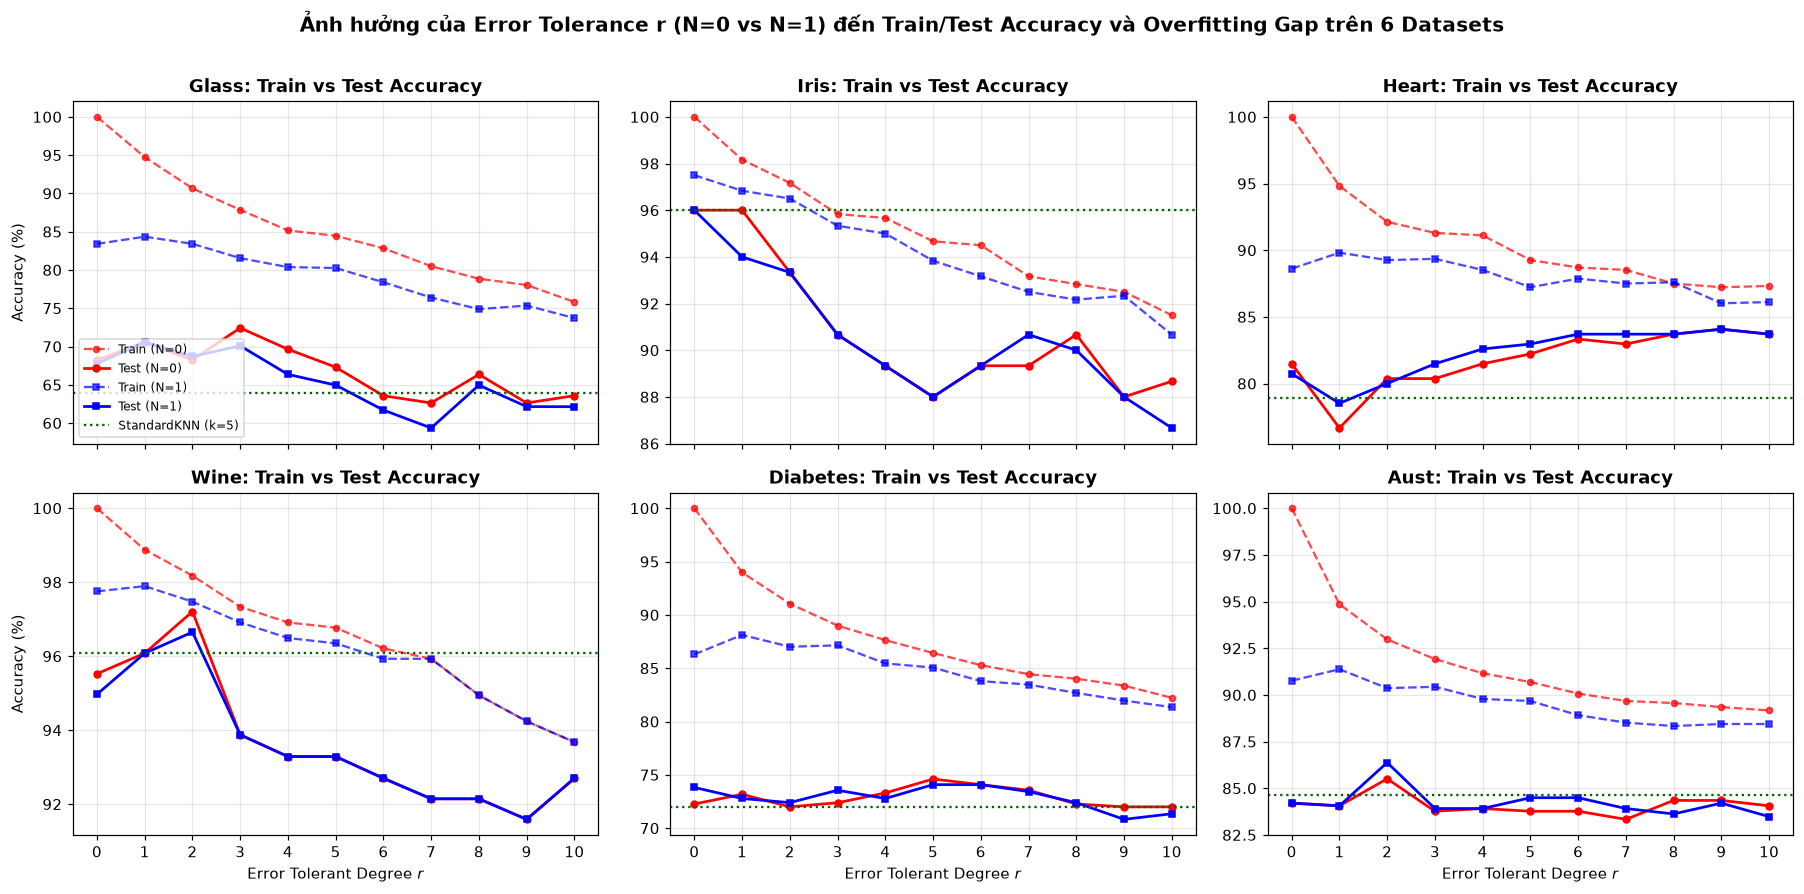

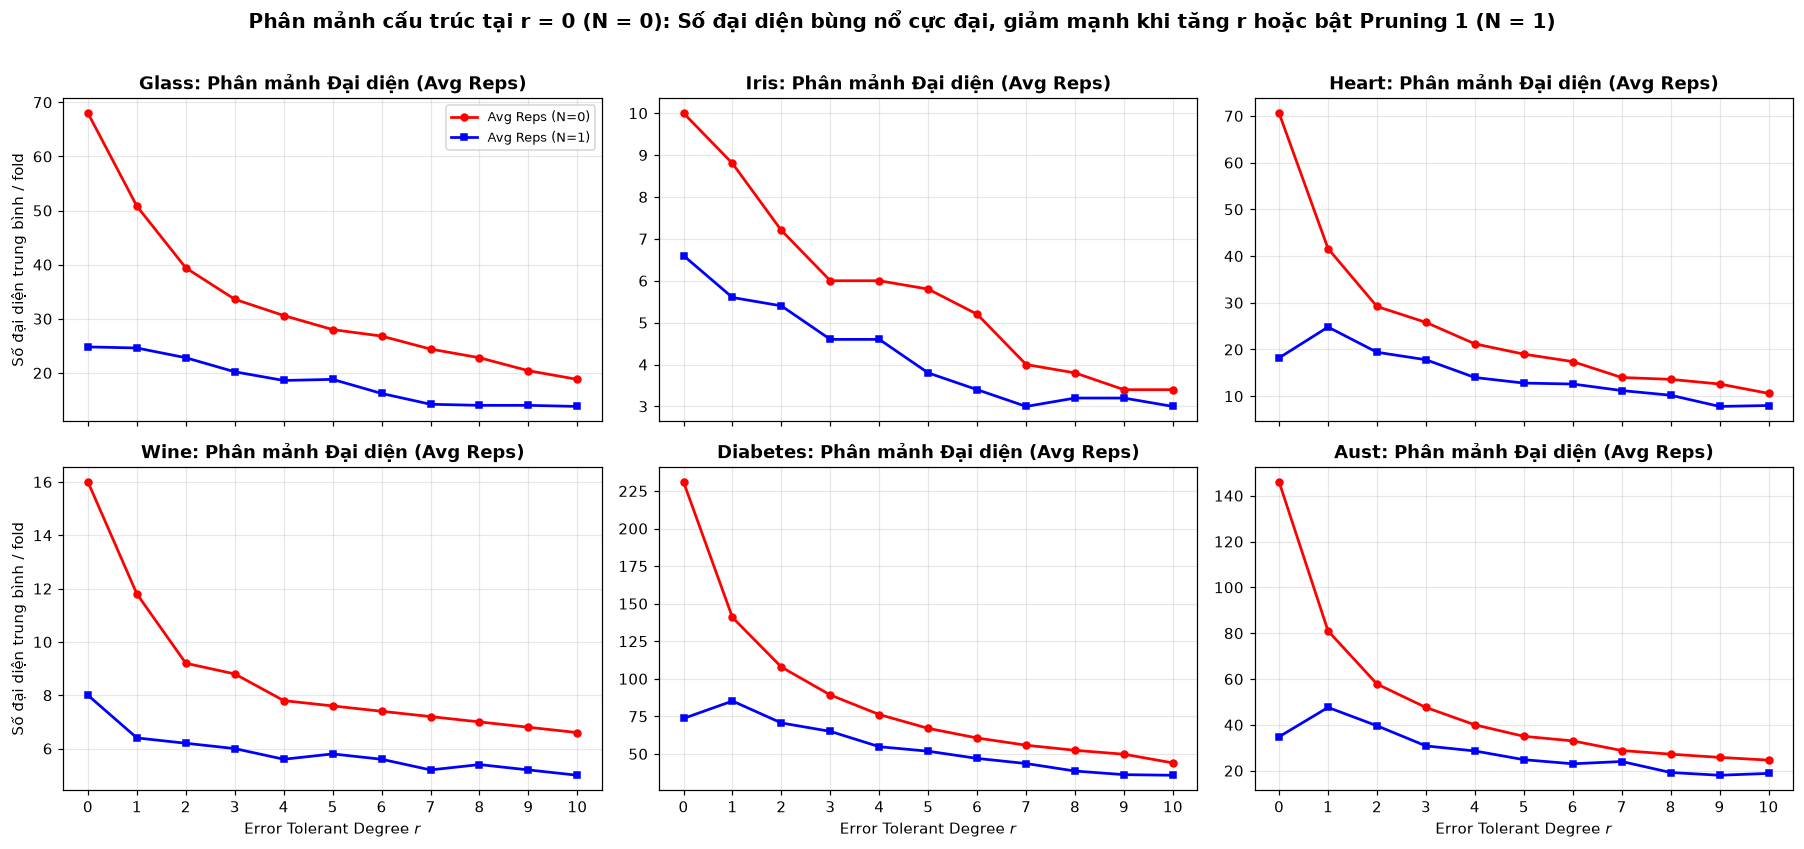

In [4]:
# Vẽ đường cong Train vs Test Accuracy và Số lượng đại diện theo r (0 -> 10) trên CẢ 6 bộ dữ liệu
r_values = list(range(0, 11))
curve_data = {}

for ds in DATASETS:
    d_rec = {
        "train_n0": [], "test_n0": [], "reps_n0": [], "rr_n0": [],
        "train_n1": [], "test_n1": [], "reps_n1": [], "rr_n1": [],
        "knn5_test": evaluate_model_detailed(ds, get_standard_knn(k=5))["test_acc"],
    }
    for r_val in r_values:
        m0 = evaluate_model_detailed(ds, KNNModel(r=r_val, N=0, metric="euclidean"))
        m1 = evaluate_model_detailed(ds, KNNModel(r=r_val, N=1, metric="euclidean"))
        d_rec["train_n0"].append(m0["train_acc"])
        d_rec["test_n0"].append(m0["test_acc"])
        d_rec["reps_n0"].append(m0["avg_reps"])
        d_rec["rr_n0"].append(m0["rr_mean"])
        d_rec["train_n1"].append(m1["train_acc"])
        d_rec["test_n1"].append(m1["test_acc"])
        d_rec["reps_n1"].append(m1["avg_reps"])
        d_rec["rr_n1"].append(m1["rr_mean"])
    curve_data[ds] = d_rec

# Hình 1A: Train vs Test Accuracy theo r (0..10) trên cả 6 datasets
fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.0), sharex=True)
for idx, (ax, ds) in enumerate(zip(axes.ravel(), DATASETS)):
    c = curve_data[ds]
    ax.plot(r_values, c["train_n0"], "r--o", markersize=4, alpha=0.7, label="Train (N=0)")
    ax.plot(r_values, c["test_n0"], "r-o", markersize=4.5, linewidth=1.8, label="Test (N=0)")
    ax.plot(r_values, c["train_n1"], "b--s", markersize=4, alpha=0.7, label="Train (N=1)")
    ax.plot(r_values, c["test_n1"], "b-s", markersize=4.5, linewidth=1.8, label="Test (N=1)")
    ax.axhline(c["knn5_test"], color="darkgreen", linestyle=":", linewidth=1.5, label="StandardKNN (k=5)")
    ax.set_title(f"{ds.capitalize()}: Train vs Test Accuracy", fontweight="bold")
    ax.set_xticks(r_values)
    ax.grid(True, alpha=0.3)
    if idx % 3 == 0:
        ax.set_ylabel("Accuracy (%)")
    if idx == 0:
        ax.legend(fontsize=8, loc="lower left")
for ax in axes[1, :]:
    ax.set_xlabel("Error Tolerant Degree $r$")

plt.suptitle(
    "Ảnh hưởng của Error Tolerance r (N=0 vs N=1) đến Train/Test Accuracy và Overfitting Gap trên 6 Datasets",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

# Hình 1B: Sự phân mảnh đại diện (Avg Reps) và Reduction Rate (%) theo r (0..10)
fig, axes = plt.subplots(2, 3, figsize=(16.5, 7.6), sharex=True)
for idx, (ax, ds) in enumerate(zip(axes.ravel(), DATASETS)):
    c = curve_data[ds]
    ax.plot(r_values, c["reps_n0"], "r-o", markersize=4.5, linewidth=1.8, label="Avg Reps (N=0)")
    ax.plot(r_values, c["reps_n1"], "b-s", markersize=4.5, linewidth=1.8, label="Avg Reps (N=1)")
    ax.set_title(f"{ds.capitalize()}: Phân mảnh Đại diện (Avg Reps)", fontweight="bold")
    ax.set_xticks(r_values)
    ax.grid(True, alpha=0.3)
    if idx % 3 == 0:
        ax.set_ylabel("Số đại diện trung bình / fold")
    if idx == 0:
        ax.legend(fontsize=8.5)
for ax in axes[1, :]:
    ax.set_xlabel("Error Tolerant Degree $r$")

plt.suptitle(
    "Phân mảnh cấu trúc tại r = 0 (N = 0): Số đại diện bùng nổ cực đại, giảm mạnh khi tăng r hoặc bật Pruning 1 (N = 1)",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

### 1.2. Thí nghiệm Tiêm Nhiễu Nhãn (Label Noise Stress Test — 3 Seeds, Đủ 6 Datasets, Tách bạch $N=0$ và $N=1$)
Trên dữ liệu sạch (Bảng 1A), `KNNModel(r=0, N=0)` vẫn có thể giữ Test Accuracy cao vì ít nhiễu nhãn; tuy nhiên bản chất học thuộc lòng sẽ lộ rõ khi tập huấn luyện xuất hiện nhiễu nhãn.
- Ta đảo ngẫu nhiên $p\% \in \{0\%, 5\%, 10\%, 15\%, 20\%\}$ nhãn trong tập Train của từng fold (lặp trung bình trên **3 random seeds** `42, 43, 44` để triệt tiêu dao động ngẫu nhiên do 1 seed đơn lẻ), trong khi **giữ tập Test sạch 100%**.
- So sánh đủ cả nhóm `N=0` (`r=0, 2, 4`), nhóm `N=1` (`r=0, 2, 4`), và `StandardKNN (k=1, 5)` trên **toàn bộ 6 datasets**.

[Glass   ] Done label-noise stress test (3 seeds) in 4.2s
[Iris    ] Done label-noise stress test (3 seeds) in 2.0s
[Heart   ] Done label-noise stress test (3 seeds) in 5.2s
[Wine    ] Done label-noise stress test (3 seeds) in 3.0s
[Diabetes] Done label-noise stress test (3 seeds) in 48.0s
[Aust    ] Done label-noise stress test (3 seeds) in 32.4s
Tổng thời gian chạy stress test: 94.8s


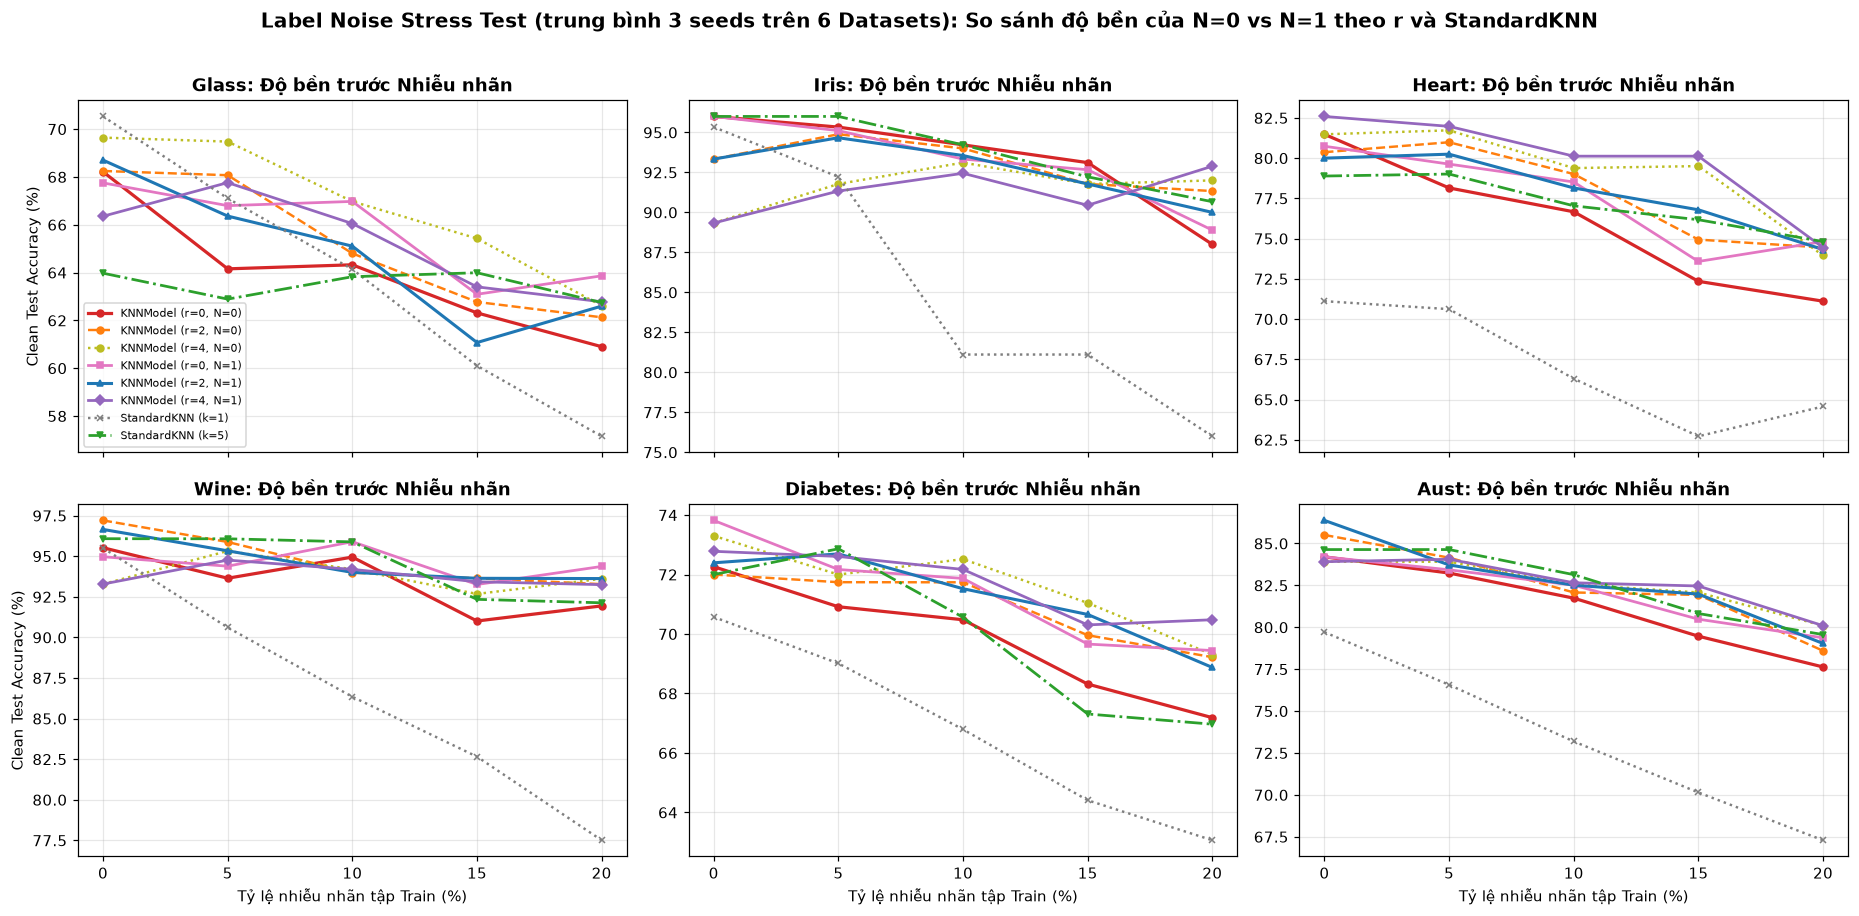

=== BẢNG 1D: TỔNG HỢP ĐỘ BỀN NHIỄU NHÃN TRUNG BÌNH TRÊN CẢ 6 DATASETS (0% -> 20%) ===


Avg Reps         Clean Test Acc (%)        RR (%)         \
Noise (%)                  0      20                  0     20      0     20   
Model                                                                          
KNNModel (r=0, N=0)    90.27  152.72              82.95  76.13  74.00  49.58   
KNNModel (r=2, N=0)    41.77   72.23              82.78  78.17  87.16  75.73   
KNNModel (r=4, N=0)    30.30   49.57              81.83  78.60  90.36  83.26   
KNNModel (r=0, N=1)    27.67   39.14              82.91  78.46  91.28  88.20   
KNNModel (r=2, N=1)    27.33   43.54              82.91  78.08  91.70  86.24   
KNNModel (r=4, N=1)    21.03   32.62              81.38  78.99  93.46  89.68   
StandardKNN (k=1)        NaN     NaN              80.46  67.60   0.00   0.00   
StandardKNN (k=5)        NaN     NaN              81.93  77.82   0.00   0.00   

                    Clean Test Acc (%)       Avg Reps  
Noise (%)                Drop (0->20%) Ratio (20%/0%)  
Model                                                  
KNNModel (r=0, N=0)               6.82           1.69  
KNNModel (r=2, N=0)               4.61           1.73  
KNNModel (r=4, N=0)               3.23           1.64  
KNNModel (r=0, N=1)               4.45           1.41  
KNNModel (r=2, N=1)               4.83           1.59  
KNNModel (r=4, N=1)               2.39           1.55  
StandardKNN (k=1)                12.86            NaN  
StandardKNN (k=5)                 4.11            NaN

=== BẢNG 1E: CHI TIẾT ĐỘ SUY GIẢM ACCURACY & BÙNG NỔ ĐẠI DIỆN THEO TỪNG DATASET ===


Avg Reps         Clean Test Acc (%)         \
Noise (%)                           0      20                  0     20   
Dataset  Model                                                            
Aust     KNNModel (r=0, N=0)    146.0  270.00              84.20  77.63   
         KNNModel (r=0, N=1)     34.8   64.27              84.20  79.37   
         KNNModel (r=2, N=0)     57.8  116.73              85.51  78.60   
         KNNModel (r=2, N=1)     39.6   73.47              86.38  79.03   
         KNNModel (r=4, N=0)     40.0   77.87              83.91  80.10   
         KNNModel (r=4, N=1)     28.6   52.73              83.91  80.10   
         StandardKNN (k=1)        NaN     NaN              79.71  67.29   
         StandardKNN (k=5)        NaN     NaN              84.64  79.57   
Diabetes KNNModel (r=0, N=0)    231.0  312.27              72.26  67.19   
         KNNModel (r=0, N=1)     73.6   96.73              73.82  69.44   
         KNNModel (r=2, N=0)    107.8  152.47              72.00  69.22   
         KNNModel (r=2, N=1)     70.6   99.40              72.39  68.87   
         KNNModel (r=4, N=0)     76.2  105.07              73.30  69.31   
         KNNModel (r=4, N=1)     54.8   75.93              72.78  70.48   
         StandardKNN (k=1)        NaN     NaN              70.57  63.07   
         StandardKNN (k=5)        NaN     NaN              72.00  66.97   
Glass    KNNModel (r=0, N=0)     68.0  106.13              68.22  60.90   
         KNNModel (r=0, N=1)     24.8   20.93              67.75  63.86   
         KNNModel (r=2, N=0)     39.4   61.00              68.25  62.13   
         KNNModel (r=2, N=1)     22.8   26.53              68.70  62.60   
         KNNModel (r=4, N=0)     30.6   43.53              69.65  62.61   
         KNNModel (r=4, N=1)     18.6   21.60              66.36  62.78   
         StandardKNN (k=1)        NaN     NaN              70.53  57.15   
         StandardKNN (k=5)        NaN     NaN              63.98  62.75   
Heart    KNNModel (r=0, N=0)     70.6  109.13              81.48  71.11   
         KNNModel (r=0, N=1)     18.2   30.67              80.74  74.81   
         KNNModel (r=2, N=0)     29.2   47.80              80.37  74.44   
         KNNModel (r=2, N=1)     19.4   31.60              80.00  74.32   
         KNNModel (r=4, N=0)     21.2   33.27              81.48  73.95   
         KNNModel (r=4, N=1)     14.0   24.13              82.59  74.44   
         StandardKNN (k=1)        NaN     NaN              71.11  64.57   
         StandardKNN (k=5)        NaN     NaN              78.89  74.81   
Iris     KNNModel (r=0, N=0)     10.0   52.33              96.00  88.00   
         KNNModel (r=0, N=1)      6.6   10.20              96.00  88.89   
         KNNModel (r=2, N=0)      7.2   22.80              93.33  91.33   
         KNNModel (r=2, N=1)      5.4   13.07              93.33  90.00   
         KNNModel (r=4, N=0)      6.0   14.73              89.33  92.00   
         KNNModel (r=4, N=1)      4.6    9.60              89.33  92.89   
         StandardKNN (k=1)        NaN     NaN              95.33  76.00   
         StandardKNN (k=5)        NaN     NaN              96.00  90.67   
Wine     KNNModel (r=0, N=0)     16.0   66.47              95.52  91.94   
         KNNModel (r=0, N=1)      8.0   12.07              94.97  94.37   
         KNNModel (r=2, N=0)      9.2   32.60              97.21  93.28   
         KNNModel (r=2, N=1)      6.2   17.20              96.65  93.62   
         KNNModel (r=4, N=0)      7.8   22.93              93.29  93.61   
         KNNModel (r=4, N=1)      5.6   11.73              93.29  93.25   
         StandardKNN (k=1)        NaN     NaN              95.51  77.51   
         StandardKNN (k=5)        NaN     NaN              96.08  92.13   

                                            
Noise (%)                    Drop (0->20%)  
Dataset  Model                              
Aust     KNNModel (r=0, N=0)          6.57  
         KNNModel (r=0,

In [5]:
def _finalize_knn_from_reps(r: int, N: int, reps, classes, n_train: int) -> KNNModel:
    m = KNNModel(r=r, N=N, metric="euclidean")
    m.classes_ = classes
    m.n_train_samples_ = n_train
    m.representatives_ = reps
    m.n_representatives_ = len(reps)
    m.reduction_rate_ = (1.0 - m.n_representatives_ / n_train) * 100.0 if n_train > 0 else 0.0
    m._rep_centers_ = np.array([rep.rep for rep in reps], dtype=np.float64)
    m._rep_sims_ = np.array([rep.sim for rep in reps], dtype=np.float64)
    return m


def evaluate_under_label_noise_ablation(
    dataset_name: str,
    noise_rates=(0.0, 0.05, 0.10, 0.15, 0.20),
    noise_seeds=(42, 43, 44),
    r_grid=(0, 2, 4),
) -> pd.DataFrame:
    """
    Tiêm nhiễu nhãn vào tập Train trong từng fold CV (trung bình nhiều seed), đánh giá trên Test sạch.
    Tái sử dụng Pass 1 giữa N=0 và N=1 cho cùng (fold, seed, noise_p, r) để tăng tốc mà kết quả giống hệt.
    """
    X, y = load_dataset(dataset_name)
    classes = np.unique(y)
    helper = KNNModel(metric="euclidean")
    model_names = (
        [f"KNNModel (r={r}, N=0)" for r in r_grid]
        + [f"KNNModel (r={r}, N=1)" for r in r_grid]
        + ["StandardKNN (k=1)", "StandardKNN (k=5)"]
    )

    rows = []
    for noise_p in noise_rates:
        seeds_to_run = (noise_seeds[0],) if noise_p == 0.0 else noise_seeds
        acc_buf = {name: [] for name in model_names}
        rep_buf = {name: [] for name in model_names}
        rr_buf = {name: [] for name in model_names}

        for s in seeds_to_run:
            for fold_idx, (train_idx, test_idx) in enumerate(CV.split(X, y)):
                rng = np.random.default_rng(s * 1000 + fold_idx * 100 + int(round(noise_p * 1000)))
                X_train, y_train = X[train_idx].copy(), y[train_idx].copy()
                X_test, y_test = X[test_idx], y[test_idx]

                n_flip = int(round(noise_p * len(y_train)))
                if n_flip > 0:
                    flip_indices = rng.choice(len(y_train), size=n_flip, replace=False)
                    for idx in flip_indices:
                        other_classes = classes[classes != y_train[idx]]
                        y_train[idx] = rng.choice(other_classes)

                prep = build_preprocessor(k="all", use_ohe=False, dataset_name=dataset_name)
                X_train_t = np.asarray(prep.fit_transform(X_train, y_train), dtype=np.float64)
                X_test_t = np.asarray(prep.transform(X_test), dtype=np.float64)
                train_classes = np.unique(y_train)
                n_train = len(X_train_t)

                # KNNModel (chia sẻ Pass 1 giữa N=0 và N=1)
                for r in r_grid:
                    pass1_reps = helper._build_model(X_train_t, y_train, r=r)

                    # N=0
                    m0 = _finalize_knn_from_reps(r, 0, pass1_reps, train_classes, n_train)
                    name0 = f"KNNModel (r={r}, N=0)"
                    acc_buf[name0].append(accuracy_score(y_test, m0.predict(X_test_t)) * 100.0)
                    rep_buf[name0].append(m0.n_representatives_)
                    rr_buf[name0].append(m0.reduction_rate_)

                    # N=1
                    weak_mask = np.zeros(n_train, dtype=bool)
                    has_pruned = False
                    for rep in pass1_reps:
                        if rep.num <= 1:
                            has_pruned = True
                            weak_mask[rep.member_indices] = True
                    if has_pruned and np.any(~weak_mask):
                        keep = ~weak_mask
                        pass2_reps = helper._build_model(X_train_t[keep], y_train[keep], r=r)
                    else:
                        pass2_reps = pass1_reps

                    m1 = _finalize_knn_from_reps(r, 1, pass2_reps, train_classes, n_train)
                    name1 = f"KNNModel (r={r}, N=1)"
                    acc_buf[name1].append(accuracy_score(y_test, m1.predict(X_test_t)) * 100.0)
                    rep_buf[name1].append(m1.n_representatives_)
                    rr_buf[name1].append(m1.reduction_rate_)

                # StandardKNN (k=1, 5)
                for k_nn in (1, 5):
                    clf = get_standard_knn(k=k_nn).fit(X_train_t, y_train)
                    k_name = f"StandardKNN (k={k_nn})"
                    acc_buf[k_name].append(accuracy_score(y_test, clf.predict(X_test_t)) * 100.0)
                    rep_buf[k_name].append(np.nan)
                    rr_buf[k_name].append(0.0)

        for name in model_names:
            rows.append({
                "Dataset": dataset_name.capitalize(),
                "Noise (%)": int(round(noise_p * 100)),
                "Model": name,
                "Clean Test Acc (%)": float(np.mean(acc_buf[name])),
                "Avg Reps": float(np.nanmean(rep_buf[name])) if not np.all(np.isnan(rep_buf[name])) else np.nan,
                "RR (%)": float(np.mean(rr_buf[name])),
            })

    return pd.DataFrame(rows)


t0 = time.perf_counter()
noise_frames = []
for ds in DATASETS:
    t_ds = time.perf_counter()
    noise_frames.append(evaluate_under_label_noise_ablation(ds))
    print(f"[{ds.capitalize():8s}] Done label-noise stress test (3 seeds) in {time.perf_counter() - t_ds:.1f}s")
df_noise_all = pd.concat(noise_frames, ignore_index=True)
print(f"Tổng thời gian chạy stress test: {time.perf_counter() - t0:.1f}s")

# Biểu đồ 2x3 trên toàn bộ 6 datasets
fig, axes = plt.subplots(2, 3, figsize=(17, 8.2), sharex=True)
styles = {
    "KNNModel (r=0, N=0)": ("#d62728", "-o", 2.1),
    "KNNModel (r=2, N=0)": ("#ff7f0e", "--o", 1.6),
    "KNNModel (r=4, N=0)": ("#bcbd22", ":o", 1.6),
    "KNNModel (r=0, N=1)": ("#e377c2", "-s", 1.8),
    "KNNModel (r=2, N=1)": ("#1f77b4", "-^", 2.0),
    "KNNModel (r=4, N=1)": ("#9467bd", "-D", 1.8),
    "StandardKNN (k=1)": ("#7f7f7f", ":x", 1.6),
    "StandardKNN (k=5)": ("#2ca02c", "-.v", 1.8),
}

for idx, (ax, ds) in enumerate(zip(axes.ravel(), DATASETS)):
    sub = df_noise_all[df_noise_all["Dataset"] == ds.capitalize()]
    for m_name, (color, fmt, lw) in styles.items():
        m_sub = sub[sub["Model"] == m_name]
        ax.plot(m_sub["Noise (%)"], m_sub["Clean Test Acc (%)"], fmt, color=color, linewidth=lw, markersize=4.5, label=m_name)
    ax.set_title(f"{ds.capitalize()}: Độ bền trước Nhiễu nhãn", fontweight="bold")
    ax.set_xticks([0, 5, 10, 15, 20])
    ax.grid(True, alpha=0.3)
    if idx % 3 == 0:
        ax.set_ylabel("Clean Test Accuracy (%)")
    if idx == 0:
        ax.legend(fontsize=7.5, loc="lower left")
for ax in axes[1, :]:
    ax.set_xlabel("Tỷ lệ nhiễu nhãn tập Train (%)")

plt.suptitle(
    "Label Noise Stress Test (trung bình 3 seeds trên 6 Datasets): So sánh độ bền của N=0 vs N=1 theo r và StandardKNN",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

# Bảng tổng hợp trung bình trên 6 datasets khi nhiễu tăng 0% -> 20%
noise_order = list(styles.keys())
df_n0_n20 = df_noise_all[df_noise_all["Noise (%)"].isin([0, 20])]
summary_noise = df_n0_n20.pivot_table(
    index="Model", columns="Noise (%)", values=["Clean Test Acc (%)", "Avg Reps", "RR (%)"], aggfunc="mean"
).reindex(noise_order)
summary_noise[("Clean Test Acc (%)", "Drop (0->20%)")] = (
    summary_noise[("Clean Test Acc (%)", 0)] - summary_noise[("Clean Test Acc (%)", 20)]
)
summary_noise[("Avg Reps", "Ratio (20%/0%)")] = (
    summary_noise[("Avg Reps", 20)] / summary_noise[("Avg Reps", 0)]
)
print("=== BẢNG 1D: TỔNG HỢP ĐỘ BỀN NHIỄU NHÃN TRUNG BÌNH TRÊN CẢ 6 DATASETS (0% -> 20%) ===")
display(summary_noise.round(2))

# Chi tiết theo từng dataset
df_drop_detail = df_n0_n20.pivot_table(
    index=["Dataset", "Model"], columns="Noise (%)", values=["Clean Test Acc (%)", "Avg Reps"]
)
df_drop_detail[("Clean Test Acc (%)", "Drop (0->20%)")] = (
    df_drop_detail[("Clean Test Acc (%)", 0)] - df_drop_detail[("Clean Test Acc (%)", 20)]
)
print("=== BẢNG 1E: CHI TIẾT ĐỘ SUY GIẢM ACCURACY & BÙNG NỔ ĐẠI DIỆN THEO TỪNG DATASET ===")
display(df_drop_detail.round(2))

### 1.3. Trực quan hóa Không gian 2D (`Diabetes`, Top-2 IG Features, chia Train/Test 80/20)
Chiếu `Diabetes` lên 2 đặc trưng có Information Gain cao nhất (fit cục bộ trên tập Train 80%) để trực quan hóa trực tiếp các hình cầu đại diện $\langle \text{Rep}(d_i), \text{Sim}(d_i) \rangle$, đại diện đơn điểm $\text{Sim}=0$ (dấu `×`), cùng cả **Train Accuracy** và **Test Accuracy**.

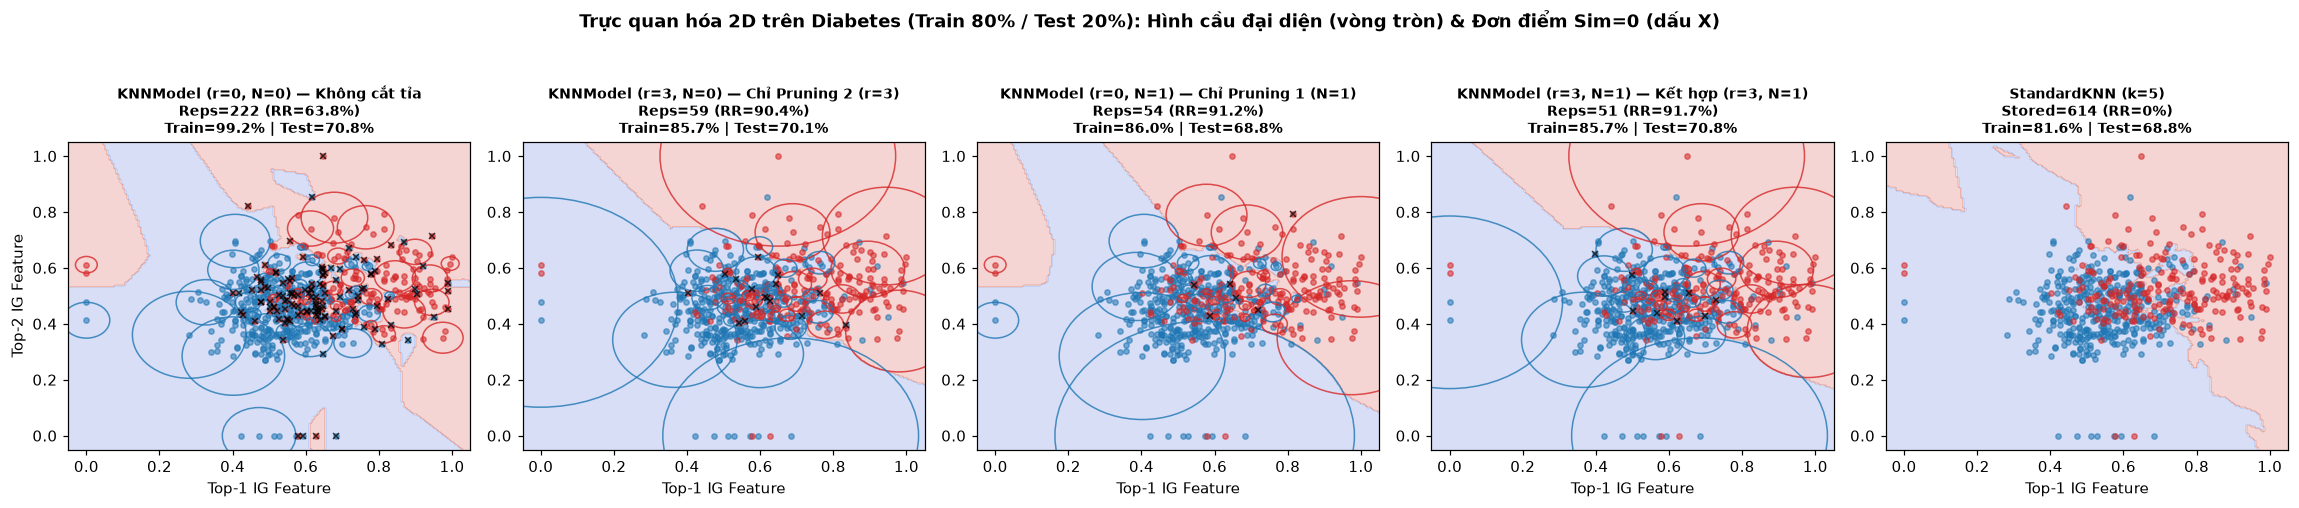

In [6]:
def plot_2d_representatives_and_boundary(dataset_name: str = "diabetes"):
    X, y = load_dataset(dataset_name)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=SEED
    )
    prep_2d = build_preprocessor(k=2, use_ohe=False, dataset_name=dataset_name)
    X_tr_2d = prep_2d.fit_transform(X_tr, y_tr)
    X_te_2d = prep_2d.transform(X_te)

    configs = [
        ("KNNModel (r=0, N=0) — Không cắt tỉa", KNNModel(r=0, N=0, metric="euclidean")),
        ("KNNModel (r=3, N=0) — Chỉ Pruning 2 (r=3)", KNNModel(r=3, N=0, metric="euclidean")),
        ("KNNModel (r=0, N=1) — Chỉ Pruning 1 (N=1)", KNNModel(r=0, N=1, metric="euclidean")),
        ("KNNModel (r=3, N=1) — Kết hợp (r=3, N=1)", KNNModel(r=3, N=1, metric="euclidean")),
        ("StandardKNN (k=5)", get_standard_knn(k=5)),
    ]

    xx, yy = np.meshgrid(np.linspace(-0.05, 1.05, 180), np.linspace(-0.05, 1.05, 180))
    grid = np.c_[xx.ravel(), yy.ravel()]
    colors = ["#1f77b4", "#d62728", "#2ca02c"]

    fig, axes = plt.subplots(1, 5, figsize=(21, 4.4))
    for ax, (title, clf) in zip(axes, configs):
        clf.fit(X_tr_2d, y_tr)
        Z = clf.predict(grid).reshape(xx.shape)
        train_acc = accuracy_score(y_tr, clf.predict(X_tr_2d)) * 100
        test_acc = accuracy_score(y_te, clf.predict(X_te_2d)) * 100

        ax.contourf(xx, yy, Z, alpha=0.22, cmap="coolwarm")
        for cls_idx in np.unique(y_tr):
            mask = y_tr == cls_idx
            ax.scatter(
                X_tr_2d[mask, 0],
                X_tr_2d[mask, 1],
                s=12,
                c=colors[int(cls_idx) % len(colors)],
                alpha=0.55,
            )

        if isinstance(clf, KNNModel):
            for rep in clf.representatives_:
                c = colors[int(rep.cls) % len(colors)]
                if rep.sim > 1e-6:
                    circle = Circle(
                        (rep.rep[0], rep.rep[1]),
                        rep.sim,
                        edgecolor=c,
                        facecolor="none",
                        linewidth=1.0,
                        alpha=0.8,
                    )
                    ax.add_patch(circle)
                else:
                    ax.plot(rep.rep[0], rep.rep[1], marker="x", color="black", markersize=4.5, alpha=0.75)
            subtitle = (
                f"{title}\nReps={clf.n_representatives_} (RR={clf.reduction_rate_:.1f}%)\n"
                f"Train={train_acc:.1f}% | Test={test_acc:.1f}%"
            )
        else:
            subtitle = f"{title}\nStored={len(X_tr_2d)} (RR=0%)\nTrain={train_acc:.1f}% | Test={test_acc:.1f}%"

        ax.set_title(subtitle, fontsize=9.2, fontweight="bold")
        ax.set_xlim(-0.05, 1.05)
        ax.set_ylim(-0.05, 1.05)
        ax.set_xlabel("Top-1 IG Feature")
    axes[0].set_ylabel("Top-2 IG Feature")
    plt.suptitle(
        f"Trực quan hóa 2D trên {dataset_name.capitalize()} (Train 80% / Test 20%): Hình cầu đại diện (vòng tròn) & Đơn điểm Sim=0 (dấu X)",
        fontsize=12,
        fontweight="bold",
        y=1.04,
    )
    plt.tight_layout()
    plt.show()


plot_2d_representatives_and_boundary("diabetes")

---
## Phần 2: Kiểm chứng Hạn chế của `KNNModel` dùng Khoảng cách Euclidean trước Dữ liệu Hỗn hợp (Nominal & Binary) & Đề xuất Cải tiến

### 2.1. Giải phẫu Ma trận Khoảng cách trên `Heart` và `Aust`: Sự lấn át của biến rời rạc, Distance Ties & Trùng tọa độ ($d = 0$)
Xét hai bộ dữ liệu hỗn hợp trong Table 1:
- **`Heart` (13 thuộc tính)**: 7 Numeric (`53.8%` số cột), 3 Nominal + 3 Binary (`46.2%` số cột).
- **`Aust` (14 thuộc tính)**: 6 Numeric (`42.9%` số cột), 4 Nominal + 4 Binary (`57.1%` số cột).

Khi dùng khoảng cách Euclidean $d(x, y) = \sqrt{\sum_j (x_j - y_j)^2}$:
1. **Lệch tỷ trọng bình phương khoảng cách ($\Delta d^2$)**: Sai khác trên biến Binary đóng góp $1^2 = 1.0$, trên biến Nominal (OHE) đóng góp $1^2 + 1^2 = 2.0$, trong khi sai khác trung bình của biến Numeric chuẩn hóa $[0, 1]$ chỉ khoảng $0.15^2 \approx 0.0225$. Hệ quả là biến rời rạc **lấn át áp đảo** tổng khoảng cách.
2. **Đồng khoảng cách (Distance Ties) và Trùng đỉnh rời rạc ($d = 0$)**: Trên không gian rời rạc, rất nhiều cặp điểm có khoảng cách bằng nhau tuyệt đối hoặc bằng $0$ (trùng toàn bộ thuộc tính nhị phân/danh nghĩa nhưng **khác nhãn lớp**). Trong `KNNModel._build_model`, lệnh `np.argsort(dist_matrix, axis=1)` phá hòa tùy ý theo thứ tự hàng, khiến hình cầu dừng sớm bất thường khi đụng điểm khác nhãn cùng khoảng cách.
3. **So sánh đối chứng với Gower Distance**: Dưới Gower Distance ($d_{\text{Gower}}(x, y) = \frac{1}{p}[\sum_{j \in \text{num}} |x_j - y_j| + \sum_{j \in \text{cat}} \mathbb{I}(x_j \neq y_j)]$), mọi thuộc tính đều nằm công bằng trong $[0, 1]$ không qua phép bình phương hay phình chiều OHE.

In [7]:
def make_mixed_preprocessor(dataset_name: str) -> tuple[Pipeline, int]:
    """
    Tiền xử lý chuẩn cho dữ liệu hỗn hợp (Gower / HEOM):
    - Các cột Numeric (0 .. n_num-1): Impute median + MinMaxScaler(clip=True) về [0, 1].
    - Các cột Nominal & Binary (n_num .. p-1): Impute mode, giữ nguyên mã danh mục (không OHE).
    """
    sc = DATASET_SCHEMA[dataset_name]
    num_cols = list(sc["numeric"])
    cat_cols = list(sc["nominal"]) + list(sc["binary"])
    transformers = []
    if num_cols:
        transformers.append((
            "num",
            Pipeline([
                ("impute", SimpleImputer(strategy="median")),
                ("scale", MinMaxScaler(clip=True)),
            ]),
            num_cols,
        ))
    if cat_cols:
        transformers.append((
            "cat",
            Pipeline([("impute", SimpleImputer(strategy="most_frequent"))]),
            cat_cols,
        ))
    return Pipeline([("columns", ColumnTransformer(transformers))]), len(num_cols)


def analyze_euclidean_distortion(dataset_name: str) -> dict:
    """Phân tích tỷ trọng khoảng cách (Euclidean Raw/OHE vs Gower), Distance Ties và trùng tọa độ d=0."""
    X, y = load_dataset(dataset_name)
    sc = DATASET_SCHEMA[dataset_name]
    num_cols = list(sc["numeric"])
    nom_cols = list(sc["nominal"])
    bin_cols = list(sc["binary"])

    # 1. Euclidean trên Raw MinMax (use_ohe=False)
    X_raw = build_preprocessor(use_ohe=False, dataset_name=dataset_name).fit_transform(X, y)
    sq_num_raw = pdist(X_raw[:, num_cols], metric="sqeuclidean").sum()
    sq_cat_raw = pdist(X_raw[:, nom_cols + bin_cols], metric="sqeuclidean").sum()
    tot_sq_raw = sq_num_raw + sq_cat_raw

    # 2. Euclidean trên One-Hot Encoding (make_preprocessor / use_ohe=True)
    X_ohe = build_preprocessor(use_ohe=True, dataset_name=dataset_name).fit_transform(X, y)
    n_num_plus_bin = len(num_cols) + len(bin_cols)
    non_nom_indices = [i for i in range(_SHAPES[dataset_name][1]) if i not in nom_cols]
    num_pos_ohe = [non_nom_indices.index(c) for c in num_cols]
    bin_pos_ohe = [non_nom_indices.index(c) for c in bin_cols]
    nom_pos_ohe = list(range(n_num_plus_bin, X_ohe.shape[1]))

    sq_num_ohe = pdist(X_ohe[:, num_pos_ohe], metric="sqeuclidean").sum()
    sq_cat_ohe = pdist(X_ohe[:, bin_pos_ohe + nom_pos_ohe], metric="sqeuclidean").sum()
    tot_sq_ohe = sq_num_ohe + sq_cat_ohe

    # 3. Gower Distance trên không gian hỗn hợp (không OHE)
    prep_mix, n_num = make_mixed_preprocessor(dataset_name)
    X_mix = prep_mix.fit_transform(X, y)
    n_cat = X_mix.shape[1] - n_num
    gower_num_sum = pdist(X_mix[:, :n_num], metric="cityblock").sum()
    gower_cat_sum = (pdist(X_mix[:, n_num:], metric="hamming") * n_cat).sum()
    gower_tot = gower_num_sum + gower_cat_sum

    # 4. Thống kê đồng khoảng cách (Distance Ties) & trùng tọa độ tuyệt đối (d == 0)
    def calc_tie_and_collision_stats(X_sub):
        D = np.round(cdist(X_sub, X_sub, metric="euclidean"), 8)
        n = len(D)
        tie_row_rates = []
        zero_pair_count = 0
        for i in range(n):
            row_d = np.delete(D[i], i)
            _, counts = np.unique(row_d, return_counts=True)
            tie_row_rates.append(np.sum(counts[counts > 1]) / (n - 1) * 100.0)
            zero_pair_count += int(np.sum(row_d == 0.0))
        unique_dists = len(np.unique(np.round(pdist(X_sub, metric="euclidean"), 6)))
        zero_rate = zero_pair_count / (n * (n - 1)) * 100.0
        return float(np.mean(tie_row_rates)), unique_dists, zero_rate

    tie_num, uniq_num, zero_num = calc_tie_and_collision_stats(X_raw[:, num_cols])
    tie_bin, uniq_bin, zero_bin = calc_tie_and_collision_stats(X_raw[:, bin_cols])
    tie_cat_raw, uniq_cat_raw, zero_cat_raw = calc_tie_and_collision_stats(X_raw[:, nom_cols + bin_cols])
    tie_cat_ohe, uniq_cat_ohe, zero_cat_ohe = calc_tie_and_collision_stats(X_ohe[:, bin_pos_ohe + nom_pos_ohe])

    n_total = len(num_cols) + len(nom_cols) + len(bin_cols)
    return {
        "Dataset": dataset_name.capitalize(),
        "Tỷ lệ số cột Numeric (%)": len(num_cols) / n_total * 100.0,
        "Tỷ lệ số cột Nominal+Binary (%)": (len(nom_cols) + len(bin_cols)) / n_total * 100.0,
        "[Euclidean Raw] % d^2 từ Numeric": sq_num_raw / tot_sq_raw * 100.0,
        "[Euclidean Raw] % d^2 từ Nominal+Binary": sq_cat_raw / tot_sq_raw * 100.0,
        "[Euclidean OHE] % d^2 từ Numeric": sq_num_ohe / tot_sq_ohe * 100.0,
        "[Euclidean OHE] % d^2 từ Nominal+Binary": sq_cat_ohe / tot_sq_ohe * 100.0,
        "[Gower Mixed] % d từ Numeric": gower_num_sum / gower_tot * 100.0,
        "[Gower Mixed] % d từ Nominal+Binary": gower_cat_sum / gower_tot * 100.0,
        "Unique Dists (Numeric Only)": uniq_num,
        "Unique Dists (Binary Only)": uniq_bin,
        "Unique Dists (Non-Numeric Raw)": uniq_cat_raw,
        "Unique Dists (Non-Numeric OHE)": uniq_cat_ohe,
        "Tie Rate % (Numeric Only)": tie_num,
        "Tie Rate % (Binary Only)": tie_bin,
        "Tie Rate % (Non-Numeric Raw)": tie_cat_raw,
        "Tie Rate % (Non-Numeric OHE)": tie_cat_ohe,
        "Exact Collision d=0 % (Numeric Only)": zero_num,
        "Exact Collision d=0 % (Binary Only)": zero_bin,
        "Exact Collision d=0 % (Non-Numeric OHE)": zero_cat_ohe,
    }


df_distortion = pd.DataFrame([analyze_euclidean_distortion(ds) for ds in ("heart", "aust")]).set_index("Dataset")
print("=== BẢNG 2A: PHÂN TÍCH TỶ TRỌNG KHOẢNG CÁCH (EUCLIDEAN VS GOWER), DISTANCE TIES & TRÙNG ĐỈNH d=0 ===")
display(df_distortion.T.round(2))

=== BẢNG 2A: PHÂN TÍCH TỶ TRỌNG KHOẢNG CÁCH (EUCLIDEAN VS GOWER), DISTANCE TIES & TRÙNG ĐỈNH d=0 ===


Dataset,Heart,Aust
Tỷ lệ số cột Numeric (%),53.85,42.86
Tỷ lệ số cột Nominal+Binary (%),46.15,57.14
[Euclidean Raw] % d^2 từ Numeric,22.63,7.31
[Euclidean Raw] % d^2 từ Nominal+Binary,77.37,92.69
[Euclidean OHE] % d^2 từ Numeric,12.93,3.00
[Euclidean OHE] % d^2 từ Nominal+Binary,87.07,97.00
[Gower Mixed] % d từ Numeric,35.28,13.91
[Gower Mixed] % d từ Nominal+Binary,64.72,86.09
Unique Dists (Numeric Only),35626.00,198553.00
Unique Dists (Binary Only),4.00,5.00


### 2.2. Thực nghiệm So sánh `KNNModel` và `StandardKNN` trên Từng Nhóm Kiểu Dữ liệu (`Numeric` vs `Binary` vs `Nominal` vs `Mixed`)
Tách riêng từng nhóm đặc trưng của `Heart` và `Aust` để thấy chính xác nơi `KNNModel` mạnh (không gian liên tục Numeric) và nơi `KNNModel` bị suy yếu nặng (ví dụ không gian `Binary Only` có mật độ trùng tọa độ $d=0$ cực lớn, hoặc khi OHE làm phình chiều và dìm tỷ trọng Numeric xuống chỉ còn 3%–13%).

In [8]:
def make_subset_preprocessor(cols_numeric=(), cols_nominal_ohe=()):
    """Tạo ColumnTransformer cho một tập con các cột Numeric/Binary và/hoặc Nominal (OHE)."""
    transformers = []
    if cols_numeric:
        transformers.append((
            "num",
            Pipeline([
                ("impute", SimpleImputer(strategy="median")),
                ("scale", MinMaxScaler()),
            ]),
            list(cols_numeric),
        ))
    if cols_nominal_ohe:
        transformers.append((
            "nom",
            Pipeline([
                ("impute", SimpleImputer(strategy="most_frequent")),
                ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]),
            list(cols_nominal_ohe),
        ))
    return Pipeline([("columns", ColumnTransformer(transformers))])


datatype_rows = []

for ds in ("heart", "aust"):
    sc = DATASET_SCHEMA[ds]
    num_cols = sc["numeric"]
    bin_cols = sc["binary"]
    nom_cols = sc["nominal"]

    subsets = [
        ("1. Numeric Only (NO)", make_subset_preprocessor(cols_numeric=num_cols)),
        ("2. Binary Only (NB)", make_subset_preprocessor(cols_numeric=bin_cols)),
        ("3. Nominal Only (NN - Raw MinMax)", make_subset_preprocessor(cols_numeric=nom_cols)),
        ("4. Nominal Only (NN - One-Hot)", make_subset_preprocessor(cols_nominal_ohe=nom_cols)),
        ("5. Non-Numeric (NN+NB - Raw MinMax)", make_subset_preprocessor(cols_numeric=nom_cols + bin_cols)),
        ("6. Non-Numeric (NN+NB - One-Hot)", make_subset_preprocessor(cols_numeric=bin_cols, cols_nominal_ohe=nom_cols)),
        ("7. All Features (Raw MinMax)", build_preprocessor(use_ohe=False, dataset_name=ds)),
        ("8. All Features (OHE - make_preprocessor)", build_preprocessor(use_ohe=True, dataset_name=ds)),
    ]

    for subset_name, prep in subsets:
        m_r0_n0 = evaluate_model_detailed(ds, KNNModel(r=0, N=0, metric="euclidean"), custom_preprocessor=prep)
        m_r0_n1 = evaluate_model_detailed(ds, KNNModel(r=0, N=1, metric="euclidean"), custom_preprocessor=prep)
        m_r1_n1 = evaluate_model_detailed(ds, KNNModel(r=1, N=1, metric="euclidean"), custom_preprocessor=prep)

        knn1 = evaluate_model_detailed(ds, get_standard_knn(k=1), custom_preprocessor=prep)["test_acc"]
        knn3 = evaluate_model_detailed(ds, get_standard_knn(k=3), custom_preprocessor=prep)["test_acc"]
        knn5 = evaluate_model_detailed(ds, get_standard_knn(k=5), custom_preprocessor=prep)["test_acc"]
        best_std_knn = max(knn1, knn3, knn5)

        datatype_rows.append({
            "Dataset": ds.capitalize(),
            "Feature Group": subset_name,
            "KNNModel(r=0,N=0) Acc%": m_r0_n0["test_acc"],
            "KNNModel(r=0,N=1) Acc%": m_r0_n1["test_acc"],
            "KNNModel(r=1,N=1) Acc%": m_r1_n1["test_acc"],
            "StandardKNN(k=1) Acc%": knn1,
            "StandardKNN(k=3) Acc%": knn3,
            "StandardKNN(k=5) Acc%": knn5,
            "Diff (r=0,N=1 vs k=5)": m_r0_n1["test_acc"] - knn5,
            "Diff (r=1,N=1 vs Best kNN)": m_r1_n1["test_acc"] - best_std_knn,
            "KNNModel(r=1) Avg Sim": m_r1_n1["avg_sim"],
            "KNNModel(r=1) RR%": m_r1_n1["rr_mean"],
        })

df_datatype_ablation = pd.DataFrame(datatype_rows)
for ds in ("Heart", "Aust"):
    print(f"=== BẢNG 2B: HIỆU NĂNG TRÊN TỪNG NHÓM KIỂU DỮ LIỆU CỦA {ds.upper()} (EUCLIDEAN) ===")
    display(df_datatype_ablation[df_datatype_ablation["Dataset"] == ds].set_index("Feature Group").round(2))

=== BẢNG 2B: HIỆU NĂNG TRÊN TỪNG NHÓM KIỂU DỮ LIỆU CỦA HEART (EUCLIDEAN) ===


,Dataset,"KNNModel(r=0,N=0) Acc%","KNNModel(r=0,N=1) Acc%","KNNModel(r=1,N=1) Acc%",StandardKNN(k=1) Acc%,StandardKNN(k=3) Acc%,StandardKNN(k=5) Acc%,"Diff (r=0,N=1 vs k=5)","Diff (r=1,N=1 vs Best kNN)",KNNModel(r=1) Avg Sim,KNNModel(r=1) RR%
Feature Group,,,,,,,,,,,
1. Numeric Only (NO),Heart,78.89,76.67,77.04,71.48,75.56,77.04,-0.37,0.00,0.33,87.41
2. Binary Only (NB),Heart,55.93,53.70,60.00,55.19,58.15,51.85,1.85,1.85,0.21,95.74
3. Nominal Only (NN - Raw MinMax),Heart,67.04,66.30,65.93,73.33,74.07,72.22,-5.93,-8.15,0.17,93.33
4. Nominal Only (NN - One-Hot),Heart,67.78,63.33,71.11,67.78,65.19,67.78,-4.44,3.33,0.40,90.93
5. Non-Numeric (NN+NB - Raw MinMax),Heart,70.37,73.33,75.19,68.89,71.85,78.15,-4.81,-2.96,0.40,87.69
6. Non-Numeric (NN+NB - One-Hot),Heart,72.96,72.22,75.93,66.30,71.11,78.52,-6.30,-2.59,0.66,87.04
7. All Features (Raw MinMax),Heart,81.48,80.74,78.52,71.11,78.15,78.89,1.85,-0.37,0.76,88.52
8. All Features (OHE - make_preprocessor),Heart,75.19,78.52,79.26,70.74,76.67,78.15,0.37,1.11,1.13,89.91


=== BẢNG 2B: HIỆU NĂNG TRÊN TỪNG NHÓM KIỂU DỮ LIỆU CỦA AUST (EUCLIDEAN) ===


,Dataset,"KNNModel(r=0,N=0) Acc%","KNNModel(r=0,N=1) Acc%","KNNModel(r=1,N=1) Acc%",StandardKNN(k=1) Acc%,StandardKNN(k=3) Acc%,StandardKNN(k=5) Acc%,"Diff (r=0,N=1 vs k=5)","Diff (r=1,N=1 vs Best kNN)",KNNModel(r=1) Avg Sim,KNNModel(r=1) RR%
Feature Group,,,,,,,,,,,
1. Numeric Only (NO),Aust,76.09,75.36,75.22,71.30,74.93,72.90,2.46,0.29,0.11,85.65
2. Binary Only (NB),Aust,74.64,74.20,78.12,82.75,84.49,84.93,-10.72,-6.81,0.31,95.98
3. Nominal Only (NN - Raw MinMax),Aust,63.19,64.20,63.04,63.77,63.04,63.91,0.29,-0.87,0.10,89.82
4. Nominal Only (NN - One-Hot),Aust,60.43,63.33,59.86,63.77,65.07,64.06,-0.72,-5.22,0.38,88.48
5. Non-Numeric (NN+NB - Raw MinMax),Aust,84.06,85.65,85.80,80.29,84.78,85.36,0.29,0.43,0.41,90.76
6. Non-Numeric (NN+NB - One-Hot),Aust,79.86,79.86,81.16,76.96,81.59,83.19,-3.33,-2.03,0.80,87.07
7. All Features (Raw MinMax),Aust,84.20,84.20,84.06,79.71,83.48,84.64,-0.43,-0.58,0.58,91.38
8. All Features (OHE - make_preprocessor),Aust,80.00,80.72,83.04,78.84,81.74,83.04,-2.32,0.00,1.03,88.62


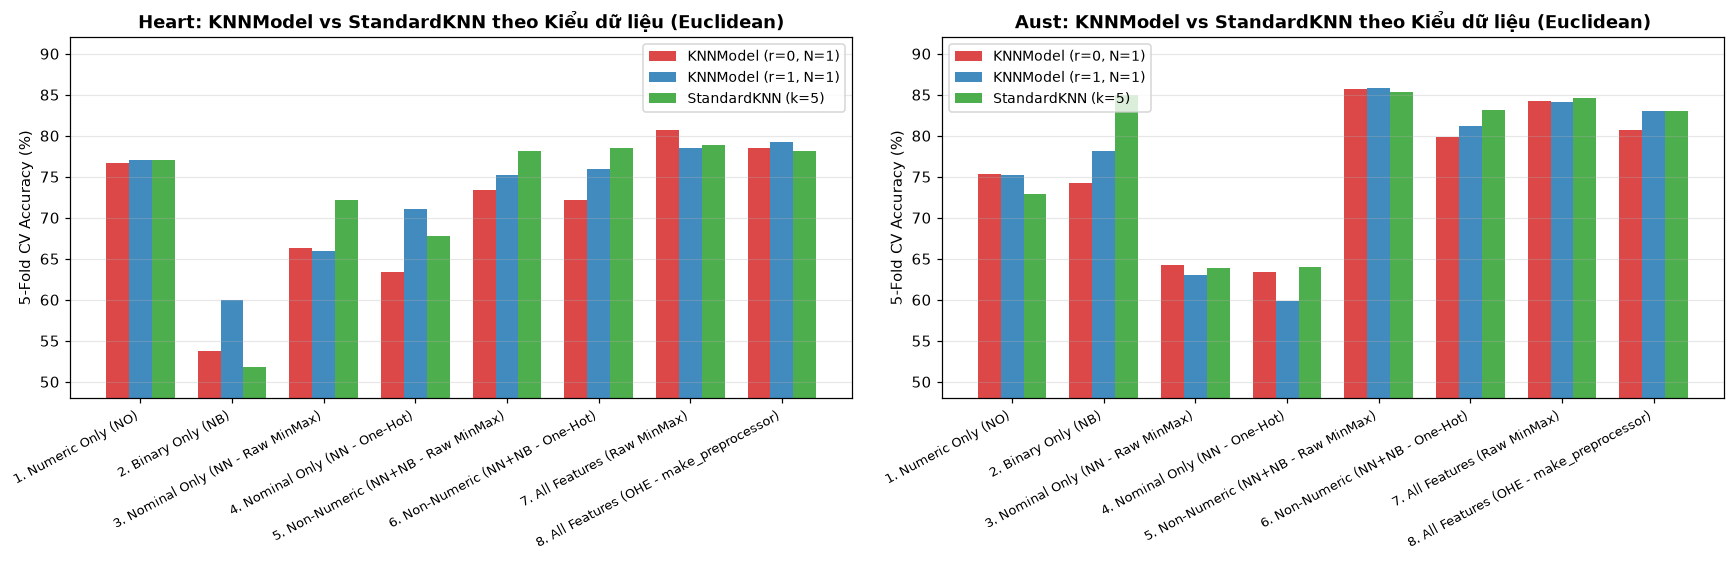

In [9]:
# Biểu đồ trực quan so sánh KNNModel (r=0, r=1) với StandardKNN (k=5) theo từng nhóm kiểu dữ liệu
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), sharey=False)

for idx, ds in enumerate(["Heart", "Aust"]):
    ax = axes[idx]
    sub = df_datatype_ablation[df_datatype_ablation["Dataset"] == ds]
    x = np.arange(len(sub))
    width = 0.25

    ax.bar(x - width, sub["KNNModel(r=0,N=1) Acc%"], width, label="KNNModel (r=0, N=1)", color="#d62728", alpha=0.85)
    ax.bar(x, sub["KNNModel(r=1,N=1) Acc%"], width, label="KNNModel (r=1, N=1)", color="#1f77b4", alpha=0.85)
    ax.bar(x + width, sub["StandardKNN(k=5) Acc%"], width, label="StandardKNN (k=5)", color="#2ca02c", alpha=0.85)

    ax.set_title(f"{ds}: KNNModel vs StandardKNN theo Kiểu dữ liệu (Euclidean)", fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["Feature Group"], rotation=28, ha="right", fontsize=8.5)
    ax.set_ylabel("5-Fold CV Accuracy (%)")
    ax.set_ylim(48, 92)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### 2.3. Kiểm chứng Tính chất Toán học của Độ đo & Đề xuất Cải tiến cho Dữ liệu Hỗn hợp (**Gower Distance** và **HEOM**)

Trong bài báo (Mục 3.2, trang 4), tác giả nhấn mạnh: *"the term 'similarity measure' could be any similarity measure such as Euclidean distance or Cosine similarity only if it is suitable for a concrete application."*

**Hai lưu ý toán học quan trọng (tránh ngộ nhận khi viết báo cáo):**
1. **Trên không gian thuần nhị phân / One-Hot (`Non-Numeric Only: NN+NB OHE`)**: Với mọi cặp vector $x, y \in \{0, 1\}^d$, gọi $m$ là số bit khác nhau, ta có $d_{L_1}(x, y) = m$, $d_{\text{Hamming}}(x, y) = m/d$, và $d_{L_2}(x, y) = \sqrt{m}$. Vì cả ba là **hàm đơn điệu tăng của nhau**, chúng tạo ra **cùng một thứ tự lân cận** (và cùng tỷ lệ Distance Ties!). Do đó, chỉ thay Euclidean bằng Manhattan hay Hamming trên không gian thuần `{0, 1}` **không giải quyết được** hiện tượng đồng khoảng cách.
2. **Không dùng Hamming trên thuộc tính số liên tục**: Với biến thực liên tục, Hamming chỉ kiểm tra $x_j \neq y_j$ nên coi độ lệch $0.001$ bằng hệt độ lệch $1.0$, làm mất hoàn toàn thông tin định lượng của thuộc tính số.

**Hướng cải tiến gắn trực tiếp với hạn chế (Mục 1.1.3 & 1.2.4):**
Thay vì ép dữ liệu hỗn hợp qua One-Hot + Euclidean, ta cài đặt hai độ đo thiết kế riêng cho dữ liệu hỗn hợp ngay trên `KNNModel` (không cần thay đổi mã nguồn lõi `knn_model.py`):
- **Gower Distance** (*Gower, 1971*):
  $$d_{\text{Gower}}(x, y) = \frac{1}{p}\left(\sum_{j \in \text{Numeric}} |x_j - y_j| + \sum_{j \in \text{Nominal} \cup \text{Binary}} \mathbb{I}(x_j \neq y_j)\right) \in [0, 1]$$
- **HEOM — Heterogeneous Euclidean-Overlap Metric** (*Wilson & Martinez, 1997 — Tài liệu tham khảo [9] của chính bài báo Guo et al., 2003*):
  $$d_{\text{HEOM}}(x, y) = \sqrt{\sum_{j \in \text{Numeric}} (x_j - y_j)^2 + \sum_{j \in \text{Nominal} \cup \text{Binary}} \mathbb{I}(x_j \neq y_j)}$$
Cả hai độ đo đều xử lý trực tiếp thuộc tính Nominal bằng phép so khớp $0/1$ (không sinh thứ tự giả như Raw MinMax và không phình chiều hay nhân hệ số $\sqrt{2}$ như One-Hot Encoding), đồng thời giữ công bằng vai trò của các thuộc tính Numeric.

In [10]:
def gower_cdist(X: np.ndarray, Y: np.ndarray, n_num: int) -> np.ndarray:
    """Khoảng cách Gower vector hóa (tốc độ C qua scipy.cdist) cho dữ liệu hỗn hợp."""
    n_total = X.shape[1]
    dist = np.zeros((len(X), len(Y)), dtype=np.float64)
    if n_num > 0:
        dist += cdist(X[:, :n_num], Y[:, :n_num], metric="cityblock")
    if n_num < n_total:
        n_cat = n_total - n_num
        dist += cdist(X[:, n_num:], Y[:, n_num:], metric="hamming") * n_cat
    return dist / n_total


def heom_cdist(X: np.ndarray, Y: np.ndarray, n_num: int) -> np.ndarray:
    """Khoảng cách HEOM (Wilson & Martinez, 1997) vector hóa cho dữ liệu hỗn hợp."""
    n_total = X.shape[1]
    sq_dist = np.zeros((len(X), len(Y)), dtype=np.float64)
    if n_num > 0:
        sq_dist += cdist(X[:, :n_num], Y[:, :n_num], metric="sqeuclidean")
    if n_num < n_total:
        n_cat = n_total - n_num
        sq_dist += cdist(X[:, n_num:], Y[:, n_num:], metric="hamming") * n_cat
    return np.sqrt(sq_dist)


class CustomDistanceKNNModel(KNNModel):
    """Mở rộng KNNModel hỗ trợ trực tiếp khoảng cách hỗn hợp Gower và HEOM."""

    def __init__(self, r: int = 0, N: int = 0, metric: str = "gower", n_num: int = 0):
        super().__init__(r=r, N=N, metric=metric)
        self.n_num = n_num

    def _pairwise_dist(self, A: np.ndarray, B: np.ndarray) -> np.ndarray:
        if self.metric == "gower":
            return gower_cdist(A, B, self.n_num)
        if self.metric == "heom":
            return heom_cdist(A, B, self.n_num)
        return cdist(A, B, metric=self.metric)

    def _build_model(self, X: np.ndarray, y: np.ndarray, r: int) -> list[Representative]:
        n_samples = len(X)
        if n_samples == 0:
            return []

        dist_matrix = self._pairwise_dist(X, X)
        sorted_all_indices = np.argsort(dist_matrix, axis=1)
        grouped = np.zeros(n_samples, dtype=bool)
        representatives: list[Representative] = []

        while not np.all(grouped):
            ungrouped_indices = np.where(~grouped)[0]
            best_candidate_idx = None
            best_sim = float("inf")
            best_num = -1
            best_covered_indices: list[int] = []

            for i in ungrouped_indices:
                target_cls = y[i]
                neighbors = sorted_all_indices[i]
                dists = dist_matrix[i, neighbors]

                current_errors = 0
                committed_covered: list[int] = [int(i)]
                committed_same_count = 1
                committed_farthest_dist = 0.0
                pending_errors: list[int] = []

                for point_idx, d_val in zip(neighbors, dists):
                    if point_idx == i:
                        continue
                    if y[point_idx] != target_cls:
                        if current_errors < r:
                            current_errors += 1
                            if not grouped[point_idx]:
                                pending_errors.append(int(point_idx))
                        else:
                            break
                    else:
                        if not grouped[point_idx]:
                            if pending_errors:
                                committed_covered.extend(pending_errors)
                                pending_errors = []
                            committed_covered.append(int(point_idx))
                            committed_same_count += 1
                            committed_farthest_dist = float(d_val)

                if (committed_same_count > best_num) or (
                    committed_same_count == best_num and committed_farthest_dist < best_sim
                ):
                    best_candidate_idx = i
                    best_num = committed_same_count
                    best_sim = committed_farthest_dist
                    best_covered_indices = committed_covered

            representatives.append(
                Representative(
                    cls=y[best_candidate_idx],
                    sim=best_sim,
                    num=len(best_covered_indices),
                    rep=X[best_candidate_idx].copy(),
                    member_indices=best_covered_indices,
                )
            )
            grouped[best_covered_indices] = True

        return representatives

    def predict_single(self, x_t: np.ndarray):
        check_is_fitted(self, attributes=["representatives_", "classes_"])
        x_arr = np.asarray(x_t, dtype=np.float64).reshape(1, -1)
        dists = self._pairwise_dist(x_arr, self._rep_centers_)[0]
        return self._predict_from_dists(dists)

    def predict(self, X) -> np.ndarray:
        check_is_fitted(self, attributes=["representatives_", "classes_"])
        X_arr = np.asarray(X, dtype=np.float64)
        dist_matrix = self._pairwise_dist(X_arr, self._rep_centers_)
        return np.array([self._predict_from_dists(dists) for dists in dist_matrix])


class MixedStandardKNN(BaseEstimator, ClassifierMixin):
    """Wrapper StandardKNN hỗ trợ khoảng cách hỗn hợp Gower / HEOM qua metric='precomputed'."""

    def __init__(self, n_neighbors: int = 5, metric: str = "gower", n_num: int = 0):
        self.n_neighbors = n_neighbors
        self.metric = metric
        self.n_num = n_num

    def _pairwise_dist(self, A: np.ndarray, B: np.ndarray) -> np.ndarray:
        if self.metric == "gower":
            return gower_cdist(A, B, self.n_num)
        if self.metric == "heom":
            return heom_cdist(A, B, self.n_num)
        return cdist(A, B, metric=self.metric)

    def fit(self, X, y):
        self._X_train_ = np.asarray(X, dtype=np.float64)
        y_arr = np.asarray(y)
        D_train = self._pairwise_dist(self._X_train_, self._X_train_)
        self._knn_ = KNeighborsClassifier(n_neighbors=self.n_neighbors, metric="precomputed")
        self._knn_.fit(D_train, y_arr)
        self.classes_ = self._knn_.classes_
        return self

    def predict(self, X):
        check_is_fitted(self, attributes=["_X_train_", "_knn_", "classes_"])
        X_arr = np.asarray(X, dtype=np.float64)
        D_test = self._pairwise_dist(X_arr, self._X_train_)
        return self._knn_.predict(D_test)


# --- BẢNG 2C-1: KIỂM CHỨNG TÍNH TƯƠNG ĐƯƠNG ĐƠN ĐIỆU TRÊN KHÔNG GIAN THUẦN {0, 1} (NN+NB OHE) ---
binary_metric_rows = []
for ds in ("heart", "aust"):
    sc = DATASET_SCHEMA[ds]
    prep_non_num = make_subset_preprocessor(cols_numeric=sc["binary"], cols_nominal_ohe=sc["nominal"])
    for dist_metric in ("euclidean", "cityblock", "hamming", "cosine"):
        m0 = evaluate_model_detailed(ds, KNNModel(r=0, N=1, metric=dist_metric), custom_preprocessor=prep_non_num)
        m1 = evaluate_model_detailed(ds, KNNModel(r=1, N=1, metric=dist_metric), custom_preprocessor=prep_non_num)
        sk5 = evaluate_model_detailed(ds, StandardKNN(n_neighbors=5, metric=dist_metric), custom_preprocessor=prep_non_num)
        binary_metric_rows.append({
            "Dataset": ds.capitalize(),
            "Metric": dist_metric,
            "KNNModel(r=0,N=1) Acc%": m0["test_acc"],
            "KNNModel(r=1,N=1) Acc%": m1["test_acc"],
            "StandardKNN(k=5) Acc%": sk5["test_acc"],
        })

df_bin_metrics = pd.DataFrame(binary_metric_rows).set_index(["Dataset", "Metric"])
print("=== BẢNG 2C-1: KIỂM CHỨNG TRÊN KHÔNG GIAN THUẦN NHỊ PHÂN (NN+NB OHE): L1, L2, HAMMING TƯƠNG ĐƯƠNG ĐƠN ĐIỆU ===")
display(df_bin_metrics.round(2))

# --- BẢNG 2C-2: SO SÁNH CÁC ĐỘ ĐO HỢP LỆ TRÊN TOÀN BỘ KHÔNG GIAN HỖN HỢP (ALL FEATURES) ---
mixed_metric_rows = []
for ds in ("heart", "aust"):
    prep_raw = build_preprocessor(use_ohe=False, dataset_name=ds)
    prep_ohe = build_preprocessor(use_ohe=True, dataset_name=ds)
    prep_mix, n_num = make_mixed_preprocessor(ds)

    metric_setups = [
        ("1. Euclidean (Raw MinMax)", prep_raw, lambda r, N: KNNModel(r=r, N=N, metric="euclidean"), lambda: StandardKNN(n_neighbors=5, metric="euclidean")),
        ("2. Euclidean (OHE)", prep_ohe, lambda r, N: KNNModel(r=r, N=N, metric="euclidean"), lambda: StandardKNN(n_neighbors=5, metric="euclidean")),
        ("3. Manhattan / L1 (OHE)", prep_ohe, lambda r, N: KNNModel(r=r, N=N, metric="cityblock"), lambda: StandardKNN(n_neighbors=5, metric="cityblock")),
        ("4. Cosine (OHE)", prep_ohe, lambda r, N: KNNModel(r=r, N=N, metric="cosine"), lambda: StandardKNN(n_neighbors=5, metric="cosine")),
        ("5. Gower Distance (Mixed - Proposed)", prep_mix, lambda r, N, nn=n_num: CustomDistanceKNNModel(r=r, N=N, metric="gower", n_num=nn), lambda nn=n_num: MixedStandardKNN(n_neighbors=5, metric="gower", n_num=nn)),
        ("6. HEOM Distance (Mixed - Proposed)", prep_mix, lambda r, N, nn=n_num: CustomDistanceKNNModel(r=r, N=N, metric="heom", n_num=nn), lambda nn=n_num: MixedStandardKNN(n_neighbors=5, metric="heom", n_num=nn)),
    ]

    for label, prep, knnm_fn, std_fn in metric_setups:
        m_r0 = evaluate_model_detailed(ds, knnm_fn(0, 1), custom_preprocessor=prep)
        m_r1 = evaluate_model_detailed(ds, knnm_fn(1, 1), custom_preprocessor=prep)
        m_r2 = evaluate_model_detailed(ds, knnm_fn(2, 1), custom_preprocessor=prep)
        sk5 = evaluate_model_detailed(ds, std_fn(), custom_preprocessor=prep)
        mixed_metric_rows.append({
            "Dataset": ds.capitalize(),
            "Distance Setup": label,
            "KNNModel(r=0,N=1) Acc%": m_r0["test_acc"],
            "KNNModel(r=1,N=1) Acc%": m_r1["test_acc"],
            "KNNModel(r=2,N=1) Acc%": m_r2["test_acc"],
            "KNNModel(r=1,N=1) RR%": m_r1["rr_mean"],
            "StandardKNN(k=5) Acc%": sk5["test_acc"],
        })

df_mixed_metrics = pd.DataFrame(mixed_metric_rows)
for ds in ("Heart", "Aust"):
    print(f"=== BẢNG 2C-2: SO SÁNH ĐỘ ĐO TRÊN KHÔNG GIAN HỖN HỢP CỦA {ds.upper()} (GOWER & HEOM VS EUCLIDEAN/L1/COSINE) ===")
    display(df_mixed_metrics[df_mixed_metrics["Dataset"] == ds].set_index("Distance Setup").drop(columns=["Dataset"]).round(2))

=== BẢNG 2C-1: KIỂM CHỨNG TRÊN KHÔNG GIAN THUẦN NHỊ PHÂN (NN+NB OHE): L1, L2, HAMMING TƯƠNG ĐƯƠNG ĐƠN ĐIỆU ===


KNNModel(r=0,N=1) Acc%  KNNModel(r=1,N=1) Acc%  \
Dataset Metric                                                      
Heart   euclidean                   72.22                   75.93   
        cityblock                   72.22                   75.93   
        hamming                     72.22                   75.93   
        cosine                      73.70                   76.30   
Aust    euclidean                   79.86                   81.16   
        cityblock                   79.86                   81.30   
        hamming                     79.86                   81.30   
        cosine                      79.57                   81.30   

                   StandardKNN(k=5) Acc%  
Dataset Metric                            
Heart   euclidean                  78.52  
        cityblock                  78.52  
        hamming                    78.52  
        cosine                     75.19  
Aust    euclidean                  83.19  
        cityblock                  82.32  
        hamming                    82.32  
        cosine                     81.16

=== BẢNG 2C-2: SO SÁNH ĐỘ ĐO TRÊN KHÔNG GIAN HỖN HỢP CỦA HEART (GOWER & HEOM VS EUCLIDEAN/L1/COSINE) ===


,"KNNModel(r=0,N=1) Acc%","KNNModel(r=1,N=1) Acc%","KNNModel(r=2,N=1) Acc%","KNNModel(r=1,N=1) RR%",StandardKNN(k=5) Acc%
Distance Setup,,,,,
1. Euclidean (Raw MinMax),80.74,78.52,80.00,88.52,78.89
2. Euclidean (OHE),78.52,79.26,76.67,89.91,78.15
3. Manhattan / L1 (OHE),80.00,78.15,76.67,88.98,79.63
4. Cosine (OHE),80.74,76.30,76.30,89.35,79.63
5. Gower Distance (Mixed - Proposed),83.33,80.00,80.74,88.80,80.37
6. HEOM Distance (Mixed - Proposed),79.63,81.85,80.74,88.61,80.00


=== BẢNG 2C-2: SO SÁNH ĐỘ ĐO TRÊN KHÔNG GIAN HỖN HỢP CỦA AUST (GOWER & HEOM VS EUCLIDEAN/L1/COSINE) ===


,"KNNModel(r=0,N=1) Acc%","KNNModel(r=1,N=1) Acc%","KNNModel(r=2,N=1) Acc%","KNNModel(r=1,N=1) RR%",StandardKNN(k=5) Acc%
Distance Setup,,,,,
1. Euclidean (Raw MinMax),84.20,84.06,86.38,91.38,84.64
2. Euclidean (OHE),80.72,83.04,81.74,88.62,83.04
3. Manhattan / L1 (OHE),82.75,81.59,83.48,89.78,83.77
4. Cosine (OHE),81.30,81.30,81.74,88.77,81.59
5. Gower Distance (Mixed - Proposed),82.32,82.32,83.33,89.60,86.67
6. HEOM Distance (Mixed - Proposed),83.77,83.19,83.33,89.67,86.23


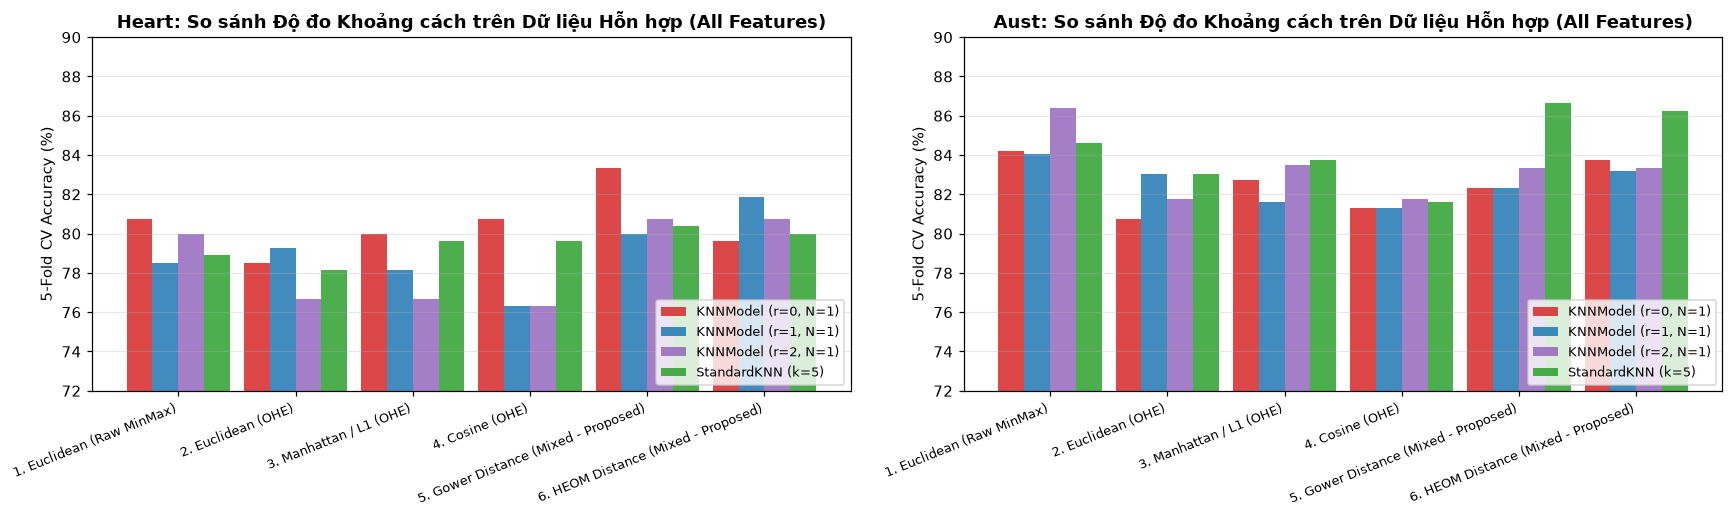

In [11]:
# Biểu đồ trực quan so sánh các độ đo trên không gian hỗn hợp (Heart & Aust)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=False)

for ax, ds in zip(axes, ["Heart", "Aust"]):
    sub = df_mixed_metrics[df_mixed_metrics["Dataset"] == ds]
    x = np.arange(len(sub))
    w = 0.22

    ax.bar(x - 1.5 * w, sub["KNNModel(r=0,N=1) Acc%"], w, label="KNNModel (r=0, N=1)", color="#d62728", alpha=0.85)
    ax.bar(x - 0.5 * w, sub["KNNModel(r=1,N=1) Acc%"], w, label="KNNModel (r=1, N=1)", color="#1f77b4", alpha=0.85)
    ax.bar(x + 0.5 * w, sub["KNNModel(r=2,N=1) Acc%"], w, label="KNNModel (r=2, N=1)", color="#9467bd", alpha=0.85)
    ax.bar(x + 1.5 * w, sub["StandardKNN(k=5) Acc%"], w, label="StandardKNN (k=5)", color="#2ca02c", alpha=0.85)

    ax.set_title(f"{ds}: So sánh Độ đo Khoảng cách trên Dữ liệu Hỗn hợp (All Features)", fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["Distance Setup"], rotation=22, ha="right", fontsize=8.5)
    ax.set_ylabel("5-Fold CV Accuracy (%)")
    ax.set_ylim(72, 90)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8.2, loc="lower right")

plt.tight_layout()
plt.show()

---
## Tổng kết Kết luận Thực nghiệm (Dùng cho Báo cáo — Mục 1.1.3 & 1.2.4)

1. **Về vai trò tách bạch của $r$ (Pruning 2) và $N$ (Pruning 1) & Hiện tượng Overfitting cấu trúc khi $r = 0$**:
   - **Khi tắt cả hai cơ chế cắt tỉa (`r=0, N=0`)**: `KNNModel` bị **học thuộc lòng cấu trúc** (Train Acc = 100%, Overfitting Gap lớn nhất, tỷ lệ đại diện đơn điểm/nhỏ rất cao, bán kính $\overline{\text{Sim}}$ nhỏ nhất) và **mất ưu thế nén dữ liệu** (RR% sụt xuống ~74% thay vì >90%). Dù trên dữ liệu sạch Test Accuracy trung bình vẫn giữ mức khá, nhưng ngay khi tập huấn luyện có nhiễu nhãn (Label Noise Stress Test), số đại diện của `(r=0, N=0)` **bùng nổ gấp nhiều lần** và độ chính xác suy giảm mạnh.
   - **Ablation `N=0` (tăng thuần $r$) vs `N=1` (bật Pruning 1)**:
     - Tăng $r$ (với `N=0`) hoạt động như một cơ chế **chính quy hóa hình học**: giảm dần Overfitting Gap, mở rộng bán kính $\overline{\text{Sim}}$ và tăng mạnh RR%. Đặc biệt trên dữ liệu có biên chồng lấn mạnh như `Diabetes`, tăng $r$ giúp cải thiện rõ rệt độ bền dưới nhiễu nhãn.
     - Bật `N=1` (với `r=0`) lại đặc biệt hiệu quả trước nhiễu nhãn ngẫu nhiên cô lập vì $r=0$ tách riêng các điểm nhiễu thành đại diện đơn điểm ($Num=1$) để bước hậu cắt tỉa `N=1` loại bỏ hoàn toàn trước lượt xây mô hình thứ 2.
     - Ngược lại, trên các tập sạch phân tách rõ như `Iris` hay `Wine`, tăng $r$ quá lớn dẫn tới **underfitting** (hình cầu tràn sang lớp khác).

2. **Về hạn chế của `KNNModel` dùng Euclidean trên dữ liệu hỗn hợp (`Heart`, `Aust`) & Cải tiến bằng Gower / HEOM**:
   - **Lệch tỷ trọng khoảng cách & Distance Ties (Bảng 2A)**: Dưới Euclidean + One-Hot Encoding, các thuộc tính Nominal và Binary chiếm **87%–97%** tổng $\Delta d^2$ (đẩy tỷ trọng của 6–7 thuộc tính Numeric xuống chỉ còn **3%–13%**!), đồng thời tạo ra tỷ lệ đồng khoảng cách **>99.8%** và tỷ lệ trùng tọa độ tuyệt đối $d=0$ cao trên không gian rời rạc.
   - **Điểm yếu đặc thù của `KNNModel` (Bảng 2B)**: Trên nhóm `Numeric Only`, `KNNModel` đạt hiệu năng ngang ngửa hoặc vượt `StandardKNN`. Tuy nhiên trên không gian rời rạc nhiều trùng lặp nhãn ở $d=0$ (đặc biệt `Aust — Binary Only`), cơ chế duyệt tuần tự `np.argsort` của `KNNModel` bị dừng sớm theo thứ tự chỉ số tùy ý, làm độ chính xác tụt sâu hơn `StandardKNN(k=5)` tới **6–11%**. Ngoài ra, áp dụng OHE trực tiếp với Euclidean làm `KNNModel (r=0)` giảm độ chính xác mạnh hơn so với `StandardKNN`.
   - **Đánh giá độ đo & Hướng cải tiến (Bảng 2C-1 & 2C-2)**:
     - Trên không gian thuần `{0, 1}` (NN+NB OHE), `euclidean`, `cityblock` và `hamming` tương đương đơn điệu nên cho kết quả gần như trùng khớp.
     - Trên không gian hỗn hợp (All Features), **Gower Distance** cân bằng lại đóng góp giữa Numeric và Nominal+Binary về sát tỷ lệ số cột thực tế (Bảng 2A), còn **Gower / HEOM** tránh được cả thứ tự giả của Raw MinMax lẫn hiệu ứng phình chiều / phạt $\sqrt{2}$ của One-Hot Encoding (so sánh số liệu chi tiết giữa 6 cấu hình độ đo tại Bảng 2C-2 sau khi chạy).